# Volatility and persistence across Vietnamese sectors

**Applied Technology in Finance and Banking · Midterm · T8 · Group 10**

**Research question.** How do volatility and its persistence differ across the Vietnamese banking, real estate, steel, technology, and consumer-goods indices?

In October 2025, IMF Managing Director Kristalina Georgieva observed that “uncertainty is the new normal.” This study asks how strongly the listed sector indices for banks, real estate, steel, technology, and consumer goods in Viet Nam respond to market shocks, and how long elevated volatility lasts. A large immediate response and a slow return to normal have different implications. The former matters for the size of a potential near-term loss. The latter matters for how long a risk manager may need to monitor an exposure after a shock. The report first measures these differences and cross-sector dynamics, then tests forecast performance and the statistical significance of the differences, and finally considers economic channels that could account for the patterns found. [Georgieva, 2025, IMF Annual Meetings curtain-raiser](https://www.imf.org/en/news/articles/2025/10/08/sp100825-annual-meetings-2025-curtain-raiser)

The outline's research question and the available workbooks cover five sectors. All five enter the analysis. Outputs 1–6 measure the data, sector dynamics, interactions and downside risk. Output 7 tests forecast quality and cross-sector differences. The final section interprets those findings using economic evidence.

Prices come from the bundled FiinPro X exports. Returns are close-to-close log changes multiplied by 100. Volatility is displayed in percent, variance in squared percent and one-session downside risk in percent log loss. See `README.md` for Python 3.12 setup and `OUTLINE_AUDIT.md` for the comparison with the previous version.

**Findings in brief.** Steel has the highest historical volatility and Consumer Goods the lowest. Banks have the highest GARCH-t persistence estimate on the training sample, and none of the ten persistence contrasts is statistically significant after Holm adjustment at either block length. The conditional correlation between Banks and Real Estate is higher in the two selected stress windows, while the exploratory VAR yields no Holm-significant Granger direction.

In [1]:
from pathlib import Path
from IPython.display import Markdown, display

from analysis_config import AnalysisConfig, AnalysisOutput
from data_processing import load_sector_data, describe_sector_data
from inference import evaluate_inference
from research_findings import write_findings
from risk_analysis import forecast_risk, backtest_risk
from sector_interactions import analyze_interactions
from time_series import (
    fit_mean_models, fit_volatility_models, forecast_volatility, publish_volatility_evaluation,
)

config = AnalysisConfig()
output = AnalysisOutput(config.output_dir, render=display, inline=True)
bootstrap_reps = 399

## Problem 1 Measurement

### Output 1 Source data synchronized returns and quality

Use the daily index closes for **Banks L1**, **Technology L1**, **Consumer Goods L1**, **Real Estate L2** and **Steel L4**. Keep the original Excel exports and match dates across their filtered series. The five baskets use different source classification levels. The audit checks observations, missing records, extreme moves and possible weekday gaps. Provider documentation and the limits of constituent coverage are recorded with the output.

The log return is $100\,[\ln(P_{i,t})-\ln(P_{i,t-1})]$. Absolute and squared returns are useful proxies for the size of price moves. An observed date gap may reflect a holiday, a market closure or an omission. The exports alone cannot establish all of those distinctions.

In [2]:
data = load_sector_data(config, output)

,Source,Rows read,Rows selected,Workbook status,Source labels selected
0,FiinProX_DE Trading data - Index_&_Sector - Gr...,14046,2967,Đã đọc,Banks L1
1,FiinProX_DE Trading data - Index_&_Sector - Gr...,40260,2967,Đã đọc,Technology L1
2,FiinProX_DE Trading data - Index_&_Sector - Gr...,135837,2967,Đã đọc,Consumer Goods L1
3,FiinProX_DE Trading data - Index_&_Sector - Gr...,28692,2967,Đã đọc,Real Estate L2
4,FiinProX_DE Trading data - Index_&_Sector - Gr...,5145,2967,Đã đọc,Steel L4


,Raw rows,Invalid date,Invalid close,Redundant valid rows,First date,Last date,Valid closes,Missing within observed span,Unchanged closes,|Daily simple change| > 10%,Returns,Status
Index/Sector,,,,,,,,,,,,
Banks L1,2967,0,0,0,2015-01-05,2026-11-20,2967,0,6,0,2966,Đủ dữ liệu mô hình
Technology L1,2967,0,0,0,2015-01-05,2026-11-20,2967,0,11,0,2966,Đủ dữ liệu mô hình
Consumer Goods L1,2967,0,0,0,2015-01-05,2026-11-20,2967,0,5,0,2966,Đủ dữ liệu mô hình
Real Estate L2,2967,0,0,0,2015-01-05,2026-11-20,2967,0,7,0,2966,Đủ dữ liệu mô hình
Steel L4,2967,0,0,0,2015-01-05,2026-11-20,2967,0,4,0,2966,Đủ dữ liệu mô hình


Lợi suất có đủ ở 5 ngành hiện có: 2,966 phiên (06/01/2015–20/11/2026).
Đủ dữ liệu để mô hình hóa: Banks L1, Technology L1, Consumer Goods L1, Real Estate L2, Steel L4
Biến động giá tuyệt đối trên 10% là cờ kiểm tra; dữ liệu quan sát vẫn được giữ nguyên.
Các khoảng có ít nhất một ngày trong tuần chưa xác minh: 57.
Xem 01_source_and_cleaning_notes.md để biết nguồn, cách đồng bộ và giới hạn về lịch, cấu phần và phương pháp chỉ số.


### Output 2 Descriptive statistics and stylized facts

Histograms, boxplots and time-series plots describe levels and returns. ADF and KPSS assess unit roots and stationarity, Jarque–Bera and Q–Q plots assess distribution shape, and the ACF and Ljung–Box assess serial dependence in signed, absolute and squared returns. Gain/loss asymmetry, the relation between shock direction and next-session squared returns, and changes across non-overlapping aggregation horizons are exploratory checks. The decision table links observations to specifications without requiring every stylized fact to hold.

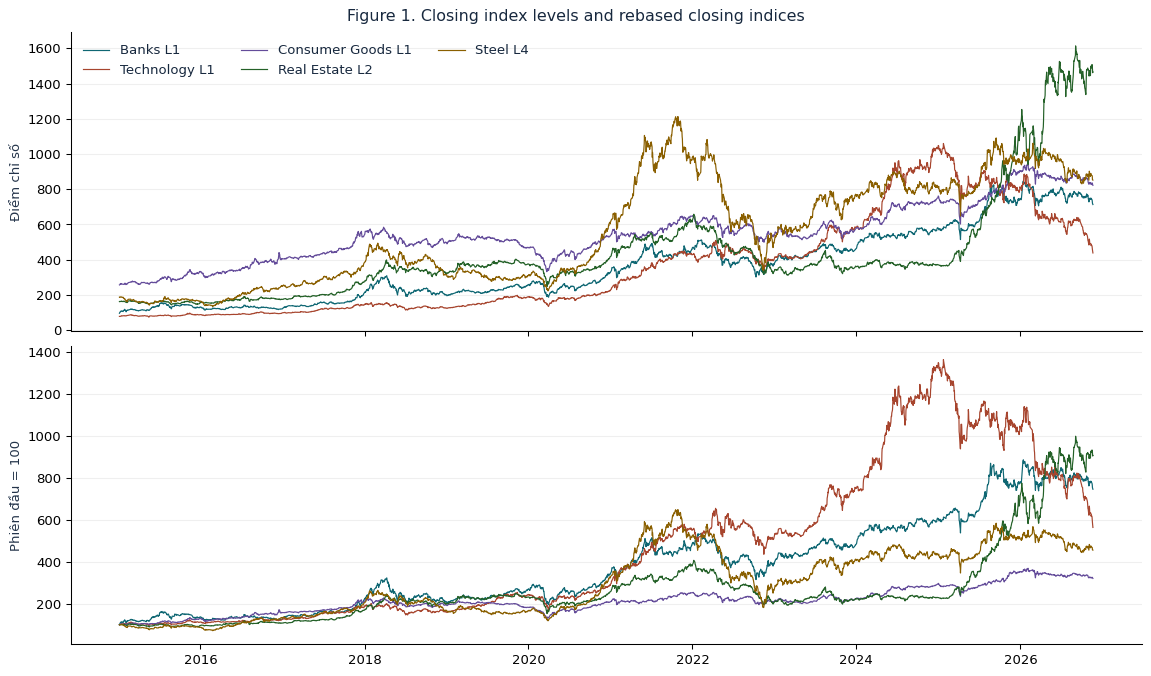

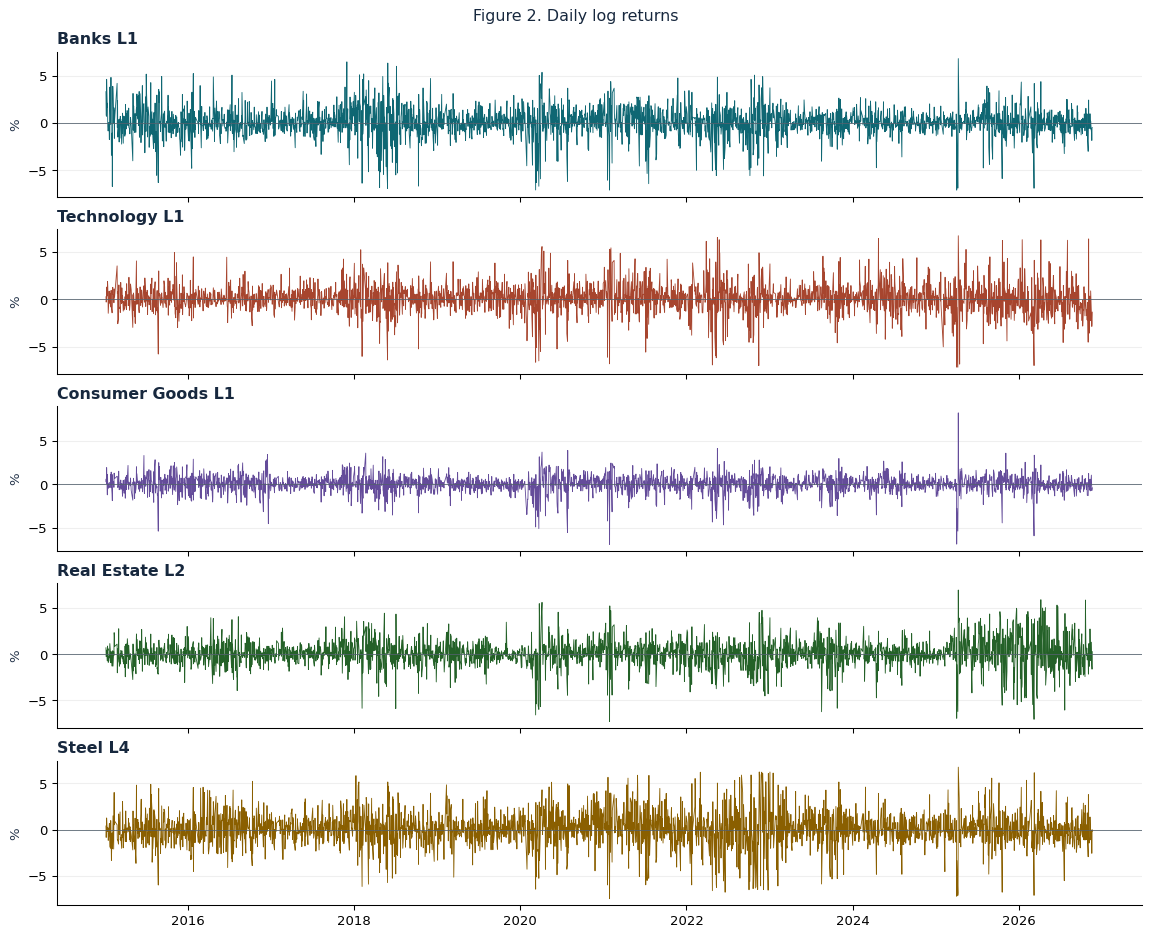

,N,Mean daily (%),SD daily (%),Vol annualized (%),Variance daily (%²),Skewness,Excess kurtosis,Minimum (%),Maximum (%),P01 (%),P05 (%),P25 (%),P50 (%),P75 (%),P95 (%),P99 (%),JB statistic,JB p-value,JB log10(p-value)
Index/Sector,,,,,,,,,,,,,,,,,,,
Banks L1,2966,0.0677,1.5141,24.0351,2.2924,-0.4685,3.7123,-7.0989,6.8401,-5.0607,-2.2648,-0.6148,0.0601,0.8137,2.3462,4.3137,1803.8671,0.0000e+00,-391.7048
Technology L1,2966,0.0583,1.4956,23.7423,2.2369,-0.1148,3.6214,-7.1908,6.7051,-4.4593,-2.2156,-0.6682,0.0528,0.7569,2.4771,4.2855,1619.9800,0.0000e+00,-351.7742
Consumer Goods L1,2966,0.0393,0.9919,15.7453,0.9838,-0.6615,6.4446,-6.9174,8.2640,-3.1046,-1.5631,-0.4087,0.0749,0.5611,1.5335,2.3906,5328.3784,0.0000e+00,-1157.0427
Real Estate L2,2966,0.0743,1.4353,22.7851,2.0602,-0.2684,3.2685,-7.2775,6.9509,-4.3661,-2.1845,-0.5590,0.0782,0.7334,2.3935,3.9938,1349.7022,8.2393e-294,-293.0841
Steel L4,2966,0.0511,1.8139,28.7955,3.2904,-0.1031,2.1084,-7.4921,6.7591,-5.5523,-2.7896,-0.8657,-0.0074,0.9881,3.1053,5.1527,551.7185,1.5698e-120,-119.8041


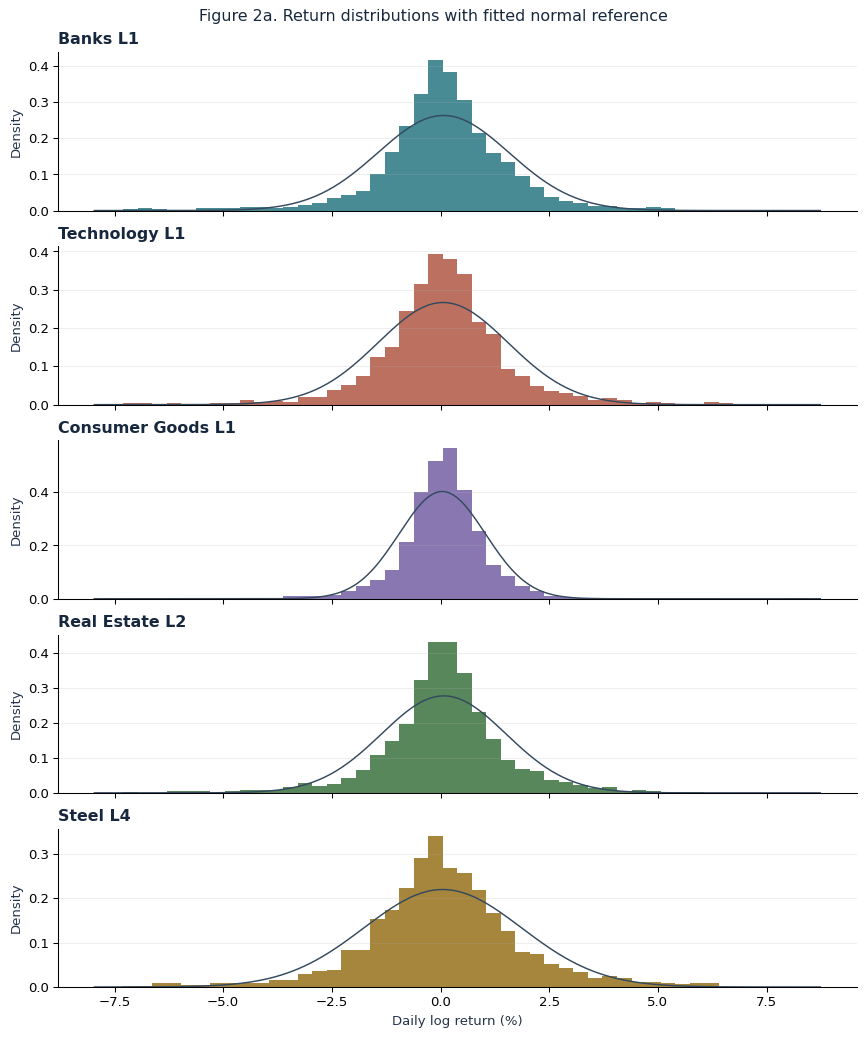

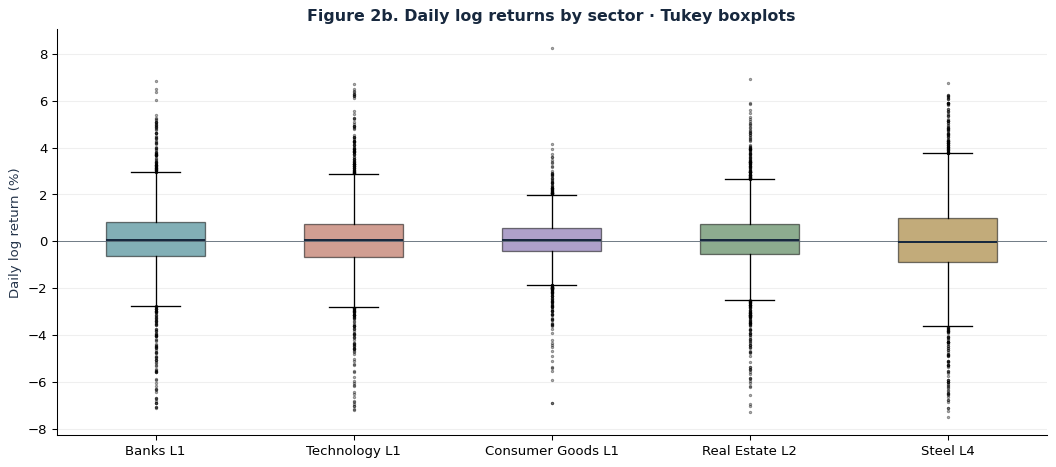

,"Vol annualized, common sample (%)",Common observations
Index/Sector,,
Banks L1,24.0351,2966
Technology L1,23.7423,2966
Consumer Goods L1,15.7453,2966
Real Estate L2,22.7851,2966
Steel L4,28.7955,2966


Index/Sector,Banks L1,Technology L1,Consumer Goods L1,Real Estate L2,Steel L4
Index/Sector,,,,,
Banks L1,1.0000,0.5748,0.5815,0.4974,0.5757
Technology L1,0.5748,1.0000,0.5462,0.4262,0.4947
Consumer Goods L1,0.5815,0.5462,1.0000,0.4986,0.5068
Real Estate L2,0.4974,0.4262,0.4986,1.0000,0.4326
Steel L4,0.5757,0.4947,0.5068,0.4326,1.0000


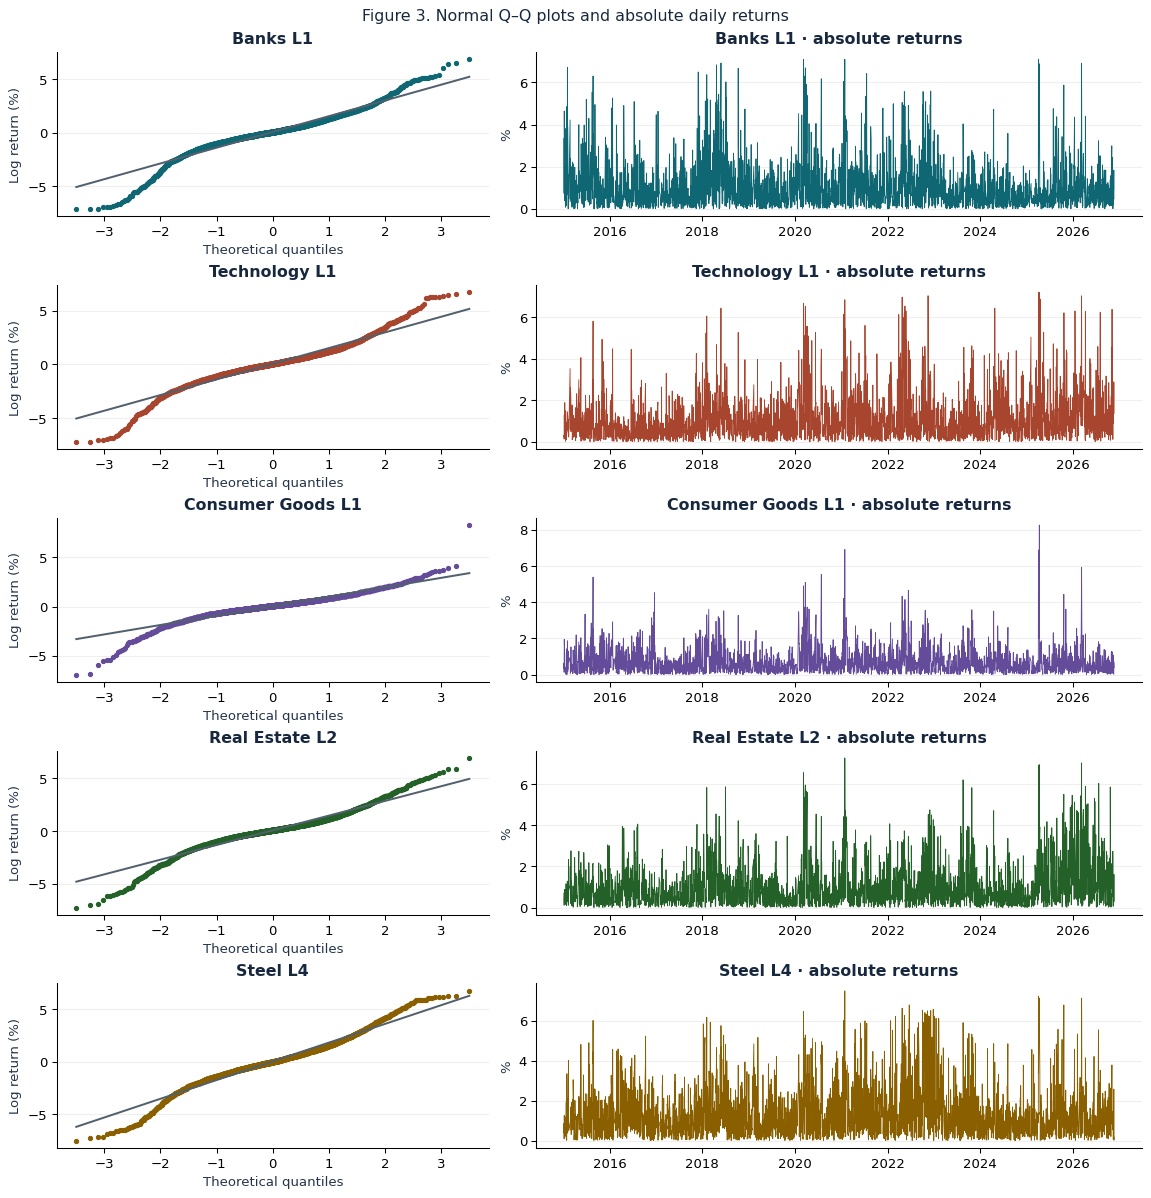

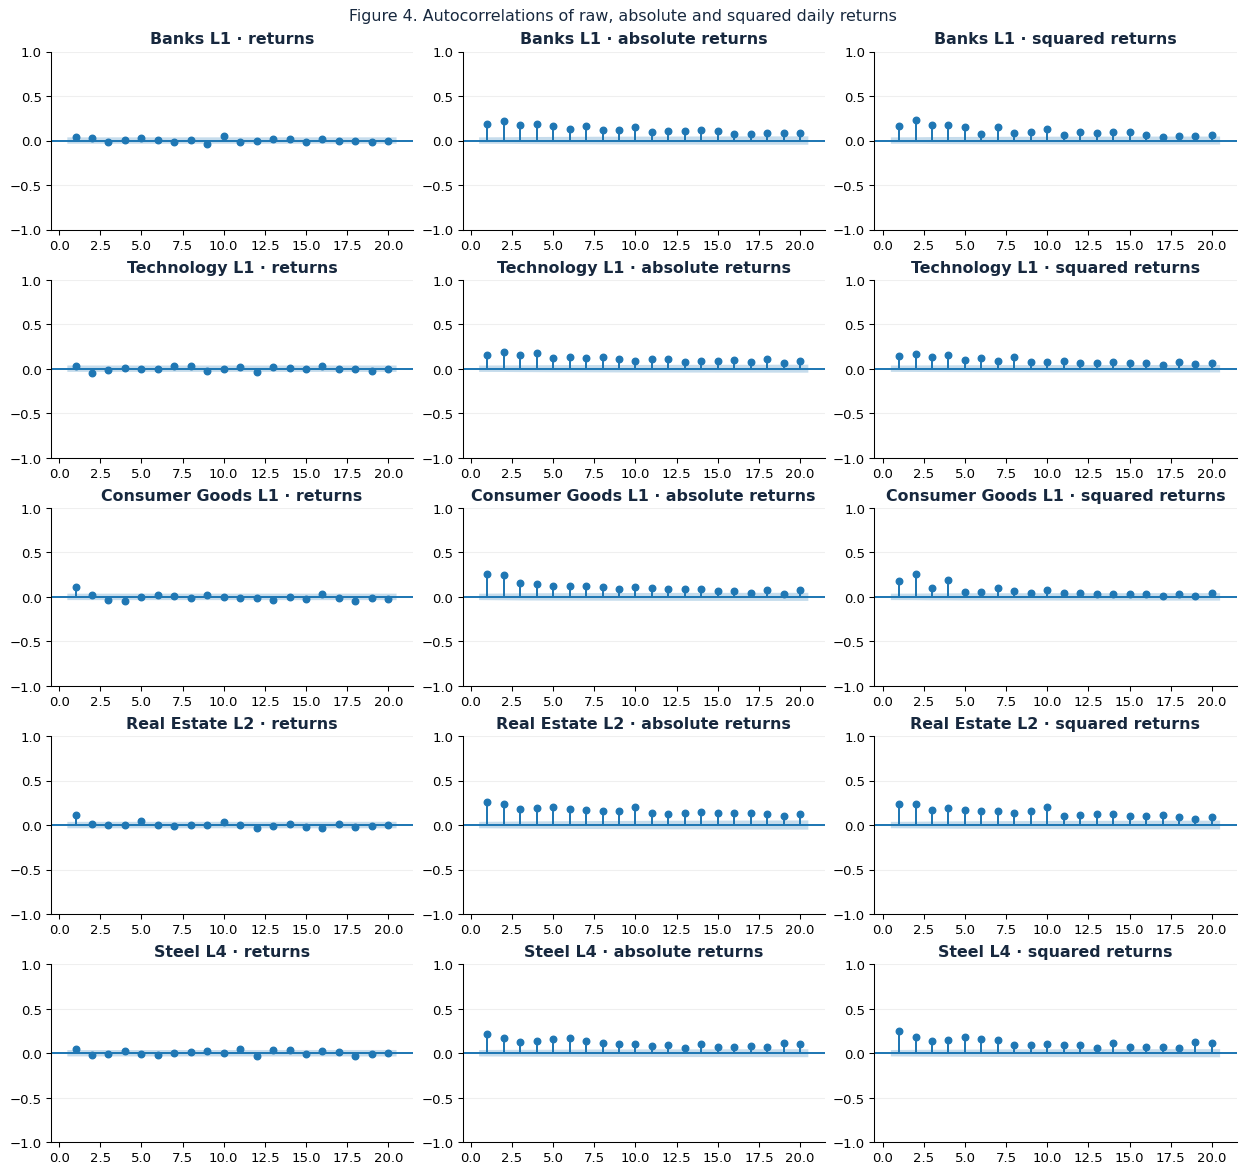

N  ADF statistic  ADF p-value  ADF lags  \
Index/Sector      Series                                                   
Banks L1          Log price   2967        -1.0694   7.2712e-01        10   
                  Log return  2966       -16.5990   1.7713e-29         9   
Technology L1     Log price   2967        -1.3837   5.9005e-01         2   
                  Log return  2966       -39.5250   0.0000e+00         1   
Consumer Goods L1 Log price   2967        -1.6894   4.3660e-01         4   
                  Log return  2966       -27.9734   0.0000e+00         3   
Real Estate L2    Log price   2967         0.5587   9.8655e-01         1   
                  Log return  2966       -48.6309   0.0000e+00         0   
Steel L4          Log price   2967        -1.3519   6.0512e-01        14   
                  Log return  2966       -12.8252   6.0338e-24        13   

                              KPSS statistic  KPSS p-value KPSS p-value bound  \
Index/Sector      Series                                                        
Banks L1          Log price           8.6943        0.0100                  <   
                  Log return          0.0528        0.1000                  >   
Technology L1     Log price           8.8186        0.0100                  <   
                  Log return          0.3890        0.0819                  =   
Consumer Goods L1 Log price           7.2637        0.0100                  <   
                  Log return          0.1037        0.1000                  >   
Real Estate L2    Log price           6.2750        0.0100                  <   
                  Log return          0.2563        0.1000                  >   
Steel L4          Log price           7.4840        0.0100                  <   
                  Log return          0.1041        0.1000                  >   

                              KPSS lags  
Index/Sector      Series                 
Banks L1          Log price          32  
                  Log return          7  
Technology L1     Log price          32  
                  Log return          5  
Consumer Goods L1 Log price          32  
                  Log return          5  
Real Estate L2    Log price          32  
                  Log return         10  
Steel L4          Log price          32  
                  Log return          4

,ACF r lag 1,"Maximum |ACF r|, lags 1–10",LB(10) r statistic,LB(10) r p-value,LB(10) absolute statistic,LB(10) absolute p-value,LB(10) squared statistic,LB(10) squared p-value,ARCH-LM(10) statistic,ARCH-LM(10) p-value
Index/Sector,,,,,,,,,,
Banks L1,0.0397,0.0495,23.6489,8.5889e-03,787.0581,1.2492e-162,679.6303,1.4792e-139,323.5901,1.5840e-63
Technology L1,0.0357,0.0443,18.9886,4.0408e-02,580.7198,2.3760e-118,444.2044,3.5984e-89,220.0144,1.0614e-41
Consumer Goods L1,0.1136,0.1136,52.3590,9.7910e-08,741.9682,6.1033e-153,506.7311,1.6084e-102,318.7409,1.6853e-62
Real Estate L2,0.1123,0.1123,46.3362,1.2464e-06,1136.9915,5.5870e-238,995.1244,2.0997e-207,386.7200,6.2966e-77
Steel L4,0.0522,0.0522,15.5915,1.1194e-01,626.7147,3.3124e-128,724.1420,4.1146e-149,323.3583,1.7736e-63


Sample evidence  \
Index/Sector      Stylized fact                                                                          
Banks L1          1. Price and return stationarity   Log prices consistent with a unit root; return...   
                  2. Heavy tails                              Excess kurtosis 3.71, JB log10(p) -391.7   
                  3. Gain/loss asymmetry             Skewness -0.47; 1% / 99% quantiles -5.06% / 4.31%   
                  4. Linear dependence               Max |ACF| at lags 1–10 is 0.050; Ljung–Box p=0...   
                  5. Volatility clustering           Absolute/squared Ljung–Box p=1.25e-162/1.48e-1...   
                  6. Asymmetric volatility response  Negative minus positive slope +0.795, explorat...   
                  7. Aggregational Gaussianity       Excess kurtosis at 1 / 5 / 20 sessions is 3.71...   
Technology L1     1. Price and return stationarity   Log prices consistent with a unit root; return...   
                  2. Heavy tails                              Excess kurtosis 3.62, JB log10(p) -351.8   
                  3. Gain/loss asymmetry             Skewness -0.11; 1% / 99% quantiles -4.46% / 4.29%   
                  4. Linear dependence               Max |ACF| at lags 1–10 is 0.044; Ljung–Box p=0...   
                  5. Volatility clustering           Absolute/squared Ljung–Box p=2.38e-118/3.6e-89...   
                  6. Asymmetric volatility response  Negative minus positive slope +0.526, explorat...   
                  7. Aggregational Gaussianity       Excess kurtosis at 1 / 5 / 20 sessions is 3.62...   
Consumer Goods L1 1. Price and return stationarity   Log prices consistent with a unit root; return...   
                  2. Heavy tails                             Excess kurtosis 6.44, JB log10(p) -1157.0   
                  3. Gain/loss asymmetry             Skewness -0.66; 1% / 99% quantiles -3.10% / 2.39%   
                  4. Linear dependence               Max |ACF| at lags 1–10 is 0.114; Ljung–Box p=9...   
                  5. Volatility clustering           Absolute/squared Ljung–Box p=6.1e-153/1.61e-10...   
                  6. Asymmetric volatility response  Negative minus positive slope +0.607, explorat...   
                  7. Aggregational Gaussianity       Excess kurtosis at 1 / 5 / 20 sessions is 6.44...   
Real Estate L2    1. Price and return stationarity   Log prices consistent with a unit root; return...   
                  2. Heavy tails                              Excess kurtosis 3.27, JB log10(p) -293.1   
                  3. Gain/loss asymmetry             Skewness -0.27; 1% / 99% quantiles -4.37% / 3.99%   
                  4. Linear dependence               Max |ACF| at lags 1–10 is 0.112; Ljung–Box p=1...   
                  5. Volatility clustering           Absolute/squared Ljung–Box p=5.59e-238/2.1e-20...   
                  6. Asymmetric volatility response  Negative minus positive slope +0.277, explorat...   
                  7. Aggregational Gaussianity       Excess kurtosis at 1 / 5 / 20 sessions is 3.27...   
Steel L4          1. Price and return stationarity   Log prices consistent with a unit root; return...   
                  2. Heavy tails                              Excess kurtosis 2.11, JB log10(p) -119.8   
                  3. Gain/loss asymmetry             Skewness -0.10; 1% / 99% quantiles -5.55% / 5.15%   
                  4. Linear dependence               Max |ACF| at lags 1–10 is 0.052; Ljung–Box p=0...   
                  5. Volatility clustering           Absolute/squared Ljung–Box p=3.31e-128/4.11e-1...   
                  6. Asymmetric volatility response  Negative minus positive slope +0.582, explorat...   
                  7. Aggregational Gaussianity       Excess kurtosis at 1 / 5 / 20 sessions is 2.11...   

                                                                                        Model decision  
Index/Sector      Stylized fact                            

Đọc các kiểm định mô tả ở mức ý nghĩa 5% cho từng kiểm định.
Sàng lọc bất đối xứng hồi quy lợi suất bình phương phiên sau trên độ lớn lợi suất đã trừ trung bình và tương tác với dấu âm. Sai số chuẩn HAC dùng 5 độ trễ. Đây là liên hệ mô tả trên toàn mẫu, bình phương lợi suất là đại diện nhiễu cho biến động và hệ số hồi quy không xác định quan hệ nhân quả.
Lợi suất 5/20 phiên là tổng log return theo các khối không chồng lấn, giữ các khối đủ dữ liệu. Đọc skewness và excess kurtosis cùng cỡ mẫu. Các p-value Jarque–Bera theo kỳ hạn có công suất khác nhau.


In [3]:
describe_sector_data(data, config, output)

### Output 3 Conditional mean and remaining ARCH effects

Use the ACF/PACF and Ljung–Box on training returns to examine serial dependence. Compare parsimonious mean equations by training-sample BIC and check the selected equation's residual Ljung–Box, ARCH-LM and squared-residual ACF. The one-step innovations from the selected equation are the input for each sector's variance models. A residual mean rejection is a diagnostic limitation to discuss. The chronological split reserves the last 25% for genuine one-session-ahead predictions.

Banks L1 · ARMA(0,0): Ljung–Box p=0.0117 trên phần dư, ARCH-LM p=1.29e-45. Có bằng chứng về ARCH, tiếp tục mô hình hóa phương sai có điều kiện.
Technology L1 · ARMA(0,0): Ljung–Box p=0.287 trên phần dư, ARCH-LM p=1.59e-36. Có bằng chứng về ARCH, tiếp tục mô hình hóa phương sai có điều kiện.
Consumer Goods L1 · ARMA(1,0): Ljung–Box p=0.388 trên phần dư, ARCH-LM p=5.64e-41. Có bằng chứng về ARCH, tiếp tục mô hình hóa phương sai có điều kiện.
Real Estate L2 · ARMA(1,0): Ljung–Box p=0.771 trên phần dư, ARCH-LM p=5.94e-56. Có bằng chứng về ARCH, tiếp tục mô hình hóa phương sai có điều kiện.
Steel L4 · ARMA(0,1): Ljung–Box p=0.251 trên phần dư, ARCH-LM p=2.92e-45. Có bằng chứng về ARCH, tiếp tục mô hình hóa phương sai có điều kiện.


,sector,train_n,train_start,train_end,test_n,test_start,test_end,rolling_window_n
0,Banks L1,2224,2015-01-06,2023-11-27,742,2023-11-28,2026-11-20,1000
1,Technology L1,2224,2015-01-06,2023-11-27,742,2023-11-28,2026-11-20,1000
2,Consumer Goods L1,2224,2015-01-06,2023-11-27,742,2023-11-28,2026-11-20,1000
3,Real Estate L2,2224,2015-01-06,2023-11-27,742,2023-11-28,2026-11-20,1000
4,Steel L4,2224,2015-01-06,2023-11-27,742,2023-11-28,2026-11-20,1000


,sector,order,AIC,BIC,raw_LB10_p,raw_ACF_significant_lags_1_to_20,residual_LB10_stat,residual_LB10_p,residual_squared_LB10_p,residual_ARCH_LM10_stat,residual_ARCH_LM10_p,variance_modelling_evidence,selection
0,Banks L1,"ARMA(0,0)",8404.2573,8415.6715,1.1728e-02,"2, 9, 10",22.7450,0.0117,6.1904e-105,238.6889,1.2914e-45,ARCH detected,Minimum BIC; no near-BIC fit clears the residu...
1,Technology L1,"ARMA(0,0)",7833.6957,7845.1098,2.8736e-01,"7, 12, 19",11.9657,0.2874,2.8376e-84,195.2400,1.5852e-36,ARCH detected,Constant mean: raw Ljung–Box does not reject
2,Consumer Goods L1,"ARMA(1,0)",6336.9380,6354.0592,2.8720e-05,"1, 11, 18",9.5558,0.3876,4.5506e-76,216.5476,5.6410e-41,ARCH detected,Parsimonious fit within 2 BIC points with no r...
3,Real Estate L2,"ARMA(1,0)",7483.0583,7500.1795,1.4460e-02,1,5.6812,0.7714,2.7344e-132,287.7797,5.9361e-56,ARCH detected,Parsimonious fit within 2 BIC points with no r...
4,Steel L4,"ARMA(0,1)",9153.3981,9170.5193,2.9312e-02,"1, 4, 11, 13",11.3773,0.2507,8.5058e-110,236.9986,2.9231e-45,ARCH detected,Parsimonious fit within 2 BIC points with no r...


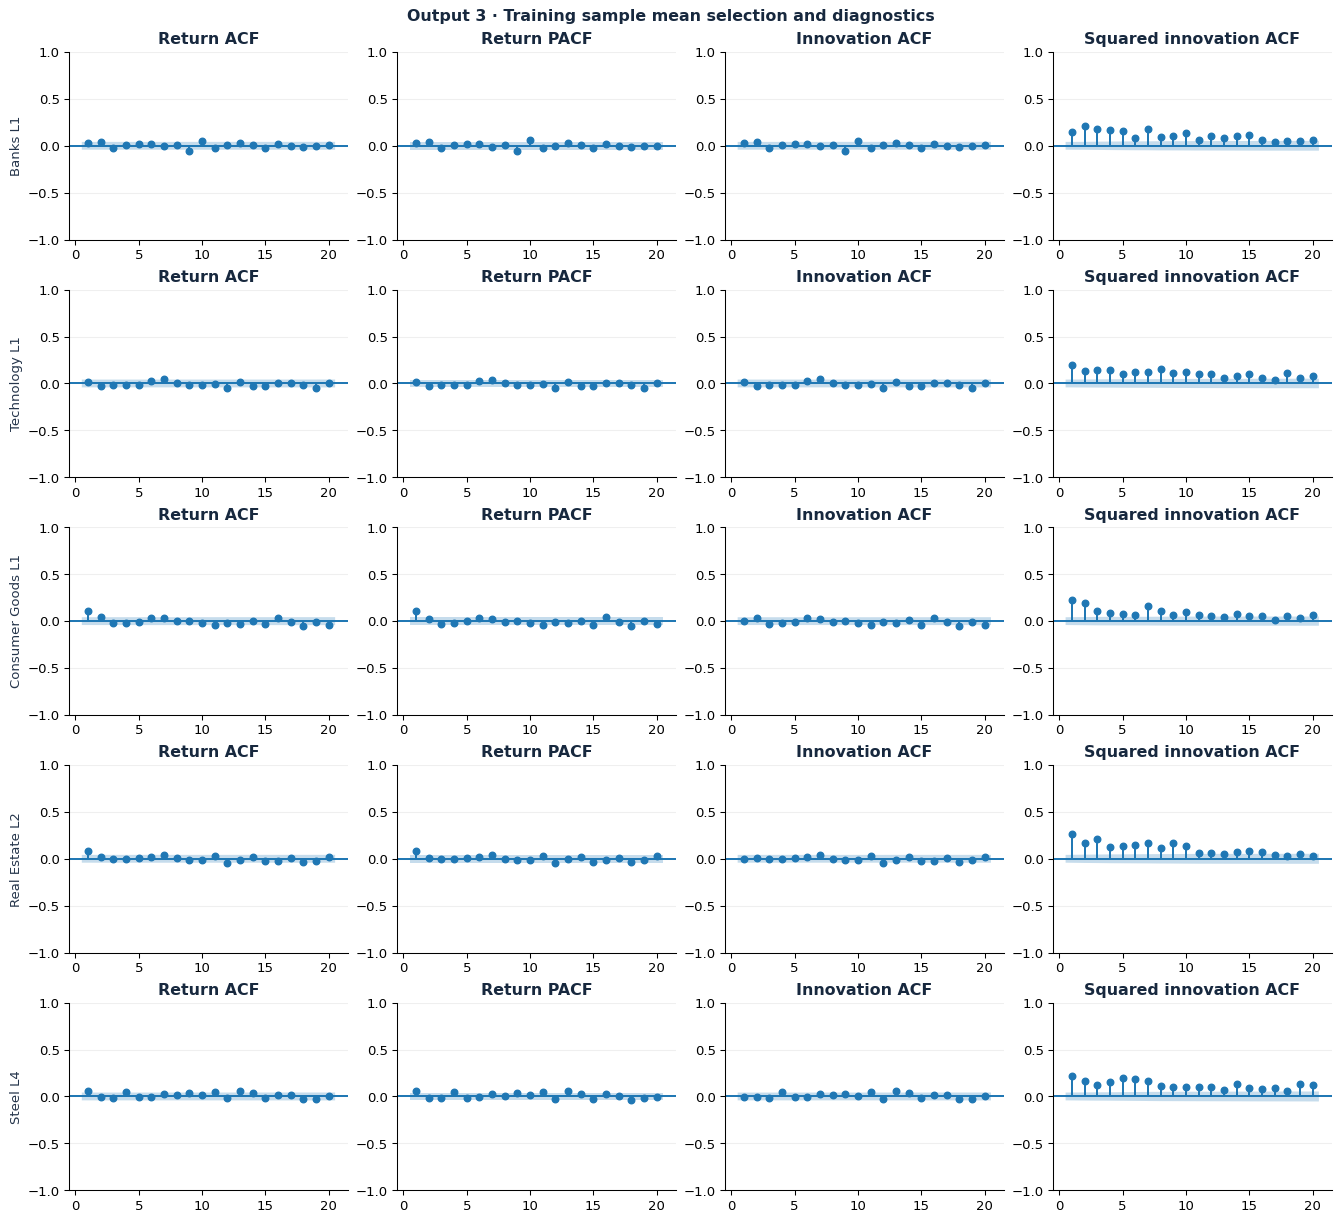

In [4]:
sample = fit_mean_models(data, config, output)

### Output 4 Sector volatility shock sensitivity and persistence

Compare a lagged 21-session rolling SD, RiskMetrics EWMA ($\lambda=0.94$), Gaussian and Student-t GARCH, Student-t GJR-GARCH and Student-t EGARCH. A GARCH(1,1) variance follows $h_{t+1}=\omega+\alpha\epsilon_t^2+\beta h_t$. Here $\alpha$ measures the immediate response and $\alpha+\beta$ measures persistence. With symmetric innovations, GJR adds $\gamma/2$ to the persistence calculation. EGARCH reports persistence on the log-variance scale. For mean-reverting persistence $p$ between zero and one, half-life is $\log(0.5)/\log(p)$. The common GARCH-t specification supports the cross-sector comparison, with GJR/EGARCH sign coefficients reported separately.

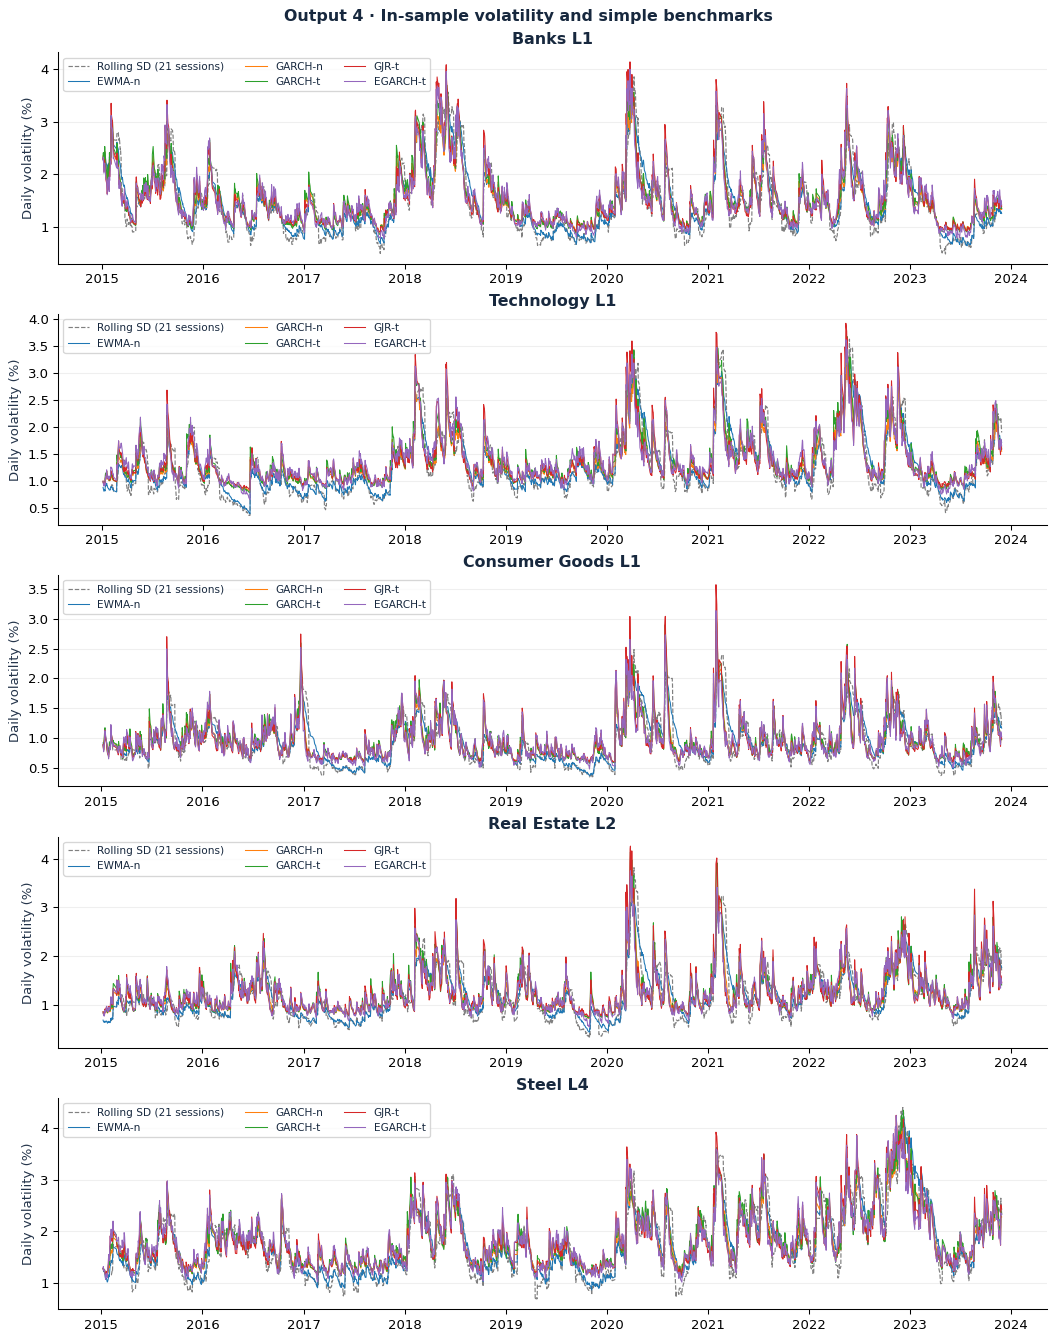

,sector,status,mean_conditional_vol_pct,alpha,alpha_p,beta,beta_p,persistence,shock_half_life_sessions,nu,admissible,mean_reverting,gamma_GJR,gamma_p_GJR,gamma_EGARCH,gamma_p_EGARCH
2,Banks L1,fit,1.5567,0.1055,1.0877e-08,0.8761,0.0000e+00,0.9816,37.4119,4.4602,True,True,0.0811,0.0239,-0.0636,0.0011
7,Technology L1,fit,1.4050,0.1090,1.0325e-08,0.8691,5.0144e-295,0.9780,31.1786,3.7475,True,True,0.0964,0.0107,-0.0509,0.0424
22,Steel L4,fit,1.8631,0.1066,2.6848e-06,0.8684,5.6035e-169,0.9750,27.3634,5.7661,True,True,0.0740,0.0112,-0.0510,0.0087
12,Consumer Goods L1,fit,0.9802,0.1658,4.6631e-06,0.7899,2.9657e-54,0.9557,15.3002,4.8815,True,True,0.1160,0.0125,-0.0802,0.0004
17,Real Estate L2,fit,1.2803,0.1772,1.3822e-05,0.7771,5.3297e-43,0.9543,14.8208,4.5321,True,True,0.1022,0.0461,-0.0485,0.0216


,sector,model,status,AIC,BIC,mean_conditional_vol_pct,omega,alpha,alpha_p,beta,beta_p,persistence,shock_half_life_sessions,gamma,gamma_p,nu,admissible,mean_reverting
0,Banks L1,EWMA-n,fit,NaN,NaN,1.4938,NaN,NaN,NaN,NaN,NaN,1.0000,NaN,NaN,NaN,NaN,True,False
1,Banks L1,GARCH-n,fit,7999.0590,8016.1802,1.5179,0.0722,0.0840,3.6538e-09,0.8871,0.0000e+00,0.9711,23.6506,NaN,NaN,NaN,True,True
2,Banks L1,GARCH-t,fit,7799.4360,7822.2643,1.5567,0.0676,0.1055,1.0877e-08,0.8761,0.0000e+00,0.9816,37.4119,NaN,NaN,4.4602,True,True
3,Banks L1,GJR-t,fit,7790.7465,7819.2818,1.5569,0.0894,0.0708,6.9729e-06,0.8611,6.4268e-162,0.9724,24.7944,0.0811,0.0239,4.4840,True,True
4,Banks L1,EGARCH-t,fit,7788.2870,7816.8223,1.5486,0.0446,0.2250,5.5472e-14,0.9643,0.0000e+00,0.9643,19.0888,-0.0636,0.0011,4.5622,True,True
5,Technology L1,EWMA-n,fit,NaN,NaN,1.3072,NaN,NaN,NaN,NaN,NaN,1.0000,NaN,NaN,NaN,NaN,True,False
6,Technology L1,GARCH-n,fit,7454.2237,7471.3449,1.3437,0.0662,0.0755,1.5672e-07,0.8904,3.9421e-286,0.9659,19.9687,NaN,NaN,NaN,True,True
7,Technology L1,GARCH-t,fit,7167.7869,7190.6151,1.4050,0.0719,0.1090,1.0325e-08,0.8691,5.0144e-295,0.9780,31.1786,NaN,NaN,3.7475,True,True
8,Technology L1,GJR-t,fit,7158.8816,7187.4169,1.4027,0.0970,0.0666,1.6476e-04,0.8514,1.2299e-211,0.9662,20.1517,0.0964,0.0107,3.7474,True,True
9,Technology L1,EGARCH-t,fit,7171.9850,7200.5203,1.4145,0.0543,0.2406,4.3895e-13,0.9561,0.0000e+00,0.9561,15.4257,-0.0509,0.0424,3.6349,True,True


In [5]:
fit = fit_volatility_models(sample, config, output)

### Output 5 VAR and CCC DCC GARCH sector interactions

Estimate VAR on the matched training returns and report lag criteria, system stability and residual whiteness. If BIC selects zero lag, the reported VAR(1) is exploratory. Granger tests assess predictive content in lagged sector returns, with Holm adjustment. Reduced-form and Cholesky impulse responses and FEVD use an explicit identification order. Reverse-order FEVD is an ordering check.

CCC sets conditional correlations constant across the sample. DCC(1,1) filters time-varying correlations from the same standardized GARCH-t margins. It follows
$Q_t=(1-a-b)\bar Q+a z_{t-1}z_{t-1}^{\prime}+bQ_{t-1}$, then rescales $Q_t$ to correlation form. Gaussian correlation likelihood and pair diagnostics describe the contrast. Regime averages are descriptive. Neither Granger nor DCC identifies a structural shock or decomposes volatility persistence into own-sector and spillover components.

,aic,bic,hqic,fpe
lag,,,,
0,1.4595,1.4724,1.4642,4.3037
1,1.4288,1.5060,1.4570,4.1735
2,1.4363,1.5779,1.4880,4.2049
3,1.4432,1.6493,1.5185,4.2343
4,1.4557,1.7261,1.5545,4.2875
5,1.4627,1.7976,1.5851,4.3178
6,1.4774,1.8766,1.6232,4.3816
7,1.4891,1.9527,1.6585,4.4331
8,1.5034,2.0314,1.6963,4.4971


,aligned_start,aligned_end,aligned_sessions,fit_observations,lag_bic,lag_aic,lag_reported,estimated_system_stable,companion_spectral_radius,portmanteau_lag,portmanteau_p_classical
0,2015-01-06,2023-11-27,2224,2223,0,1,1,True,0.0867,12,0.0017


,predictor,response,lag,classical_F,classical_p,HAC_Wald,HAC_p,HAC_Holm_p,reject_at_configured_level
0,Technology L1,Real Estate L2,1,6.9117,0.0086,6.0687,0.0138,0.2752,False
1,Technology L1,Consumer Goods L1,1,7.3828,0.0066,5.7859,0.0162,0.3070,False
2,Steel L4,Consumer Goods L1,1,3.8051,0.0511,4.5463,0.0330,0.5938,False
3,Banks L1,Technology L1,1,2.0078,0.1565,2.2842,0.1307,1.0000,False
4,Banks L1,Steel L4,1,0.6667,0.4142,0.6031,0.4374,1.0000,False
5,Banks L1,Real Estate L2,1,1.6114,0.2043,1.4790,0.2239,1.0000,False
6,Technology L1,Banks L1,1,0.9339,0.3339,0.7008,0.4025,1.0000,False
7,Banks L1,Consumer Goods L1,1,0.0020,0.9641,0.0021,0.9632,1.0000,False
8,Consumer Goods L1,Banks L1,1,0.0053,0.9418,0.0052,0.9424,1.0000,False
9,Consumer Goods L1,Technology L1,1,0.4395,0.5074,0.3482,0.5551,1.0000,False


BIC chọn VAR(0). Các kiểm định động dưới VAR(1) mang tính thăm dò.
Granger HAC–Holm: 0/20 hướng có p < 0.05.


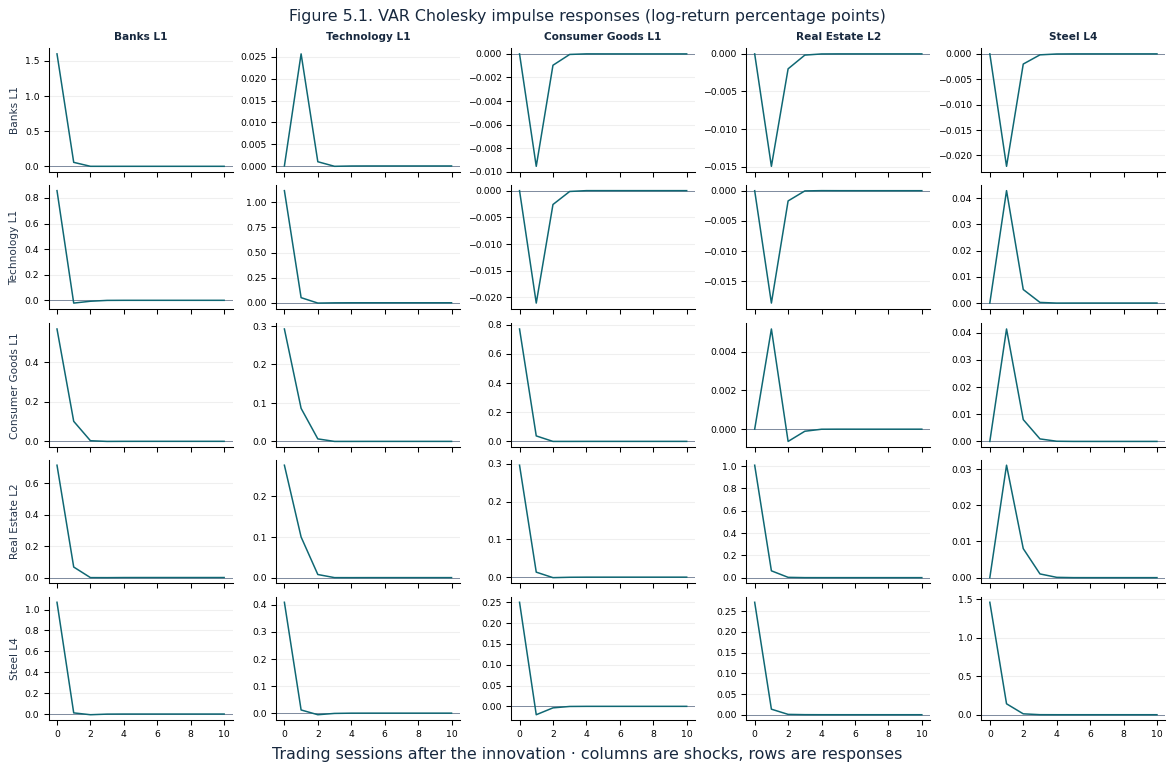

shock_sector,Banks L1,Technology L1,Consumer Goods L1,Real Estate L2,Steel L4
response_sector,,,,,
Banks L1,99.9423,0.0258,0.0036,0.0089,0.0194
Technology L1,37.0030,62.8628,0.0227,0.0177,0.0939
Consumer Goods L1,32.6026,9.0614,58.1604,0.0027,0.1729
Real Estate L2,30.0671,5.0817,5.1502,59.6406,0.0604
Steel L4,31.7604,4.6434,1.7408,2.0505,59.8049


FEVD chân trời 10 phiên: chênh lệch ô lớn nhất khi đảo thứ tự Cholesky = 51.5 điểm phần trăm.


,model,observations,alpha_dcc,beta_dcc,alpha_plus_beta,gaussian_correlation_loglik,fit_start,fit_end,gain_from_CCC,at_persistence_constraint
0,CCC-GARCH-t,2223,0.0000,NaN,NaN,1858.2489,2015-01-07,2023-11-27,0.0000,False
1,DCC-GARCH-t,2223,0.0269,0.9515,0.9784,2027.9955,2015-01-07,2023-11-27,169.7465,False


,sector_a,sector_b,CCC_constant_corr,DCC_mean_corr,DCC_sd_corr,DCC_p05_corr,DCC_p95_corr,CCC_pair_HAC_p,DCC_pair_HAC_p,CCC_pair_Holm_p,DCC_pair_Holm_p
0,Banks L1,Technology L1,0.5474,0.5408,0.1099,0.3538,0.7109,0.2488,0.8441,0.7915,1.0000
1,Banks L1,Consumer Goods L1,0.5212,0.5121,0.1128,0.3446,0.7064,0.1319,0.7057,0.7915,1.0000
2,Banks L1,Real Estate L2,0.5195,0.5130,0.1168,0.2988,0.6832,0.4439,0.9807,0.7915,1.0000
3,Banks L1,Steel L4,0.5264,0.5189,0.1111,0.3446,0.6952,0.0393,0.6050,0.3148,1.0000
4,Technology L1,Consumer Goods L1,0.5051,0.4938,0.1102,0.3173,0.6711,0.3149,0.7157,0.7915,1.0000
5,Technology L1,Real Estate L2,0.4547,0.4469,0.0996,0.2910,0.6168,0.1622,0.3070,0.7915,1.0000
6,Technology L1,Steel L4,0.4699,0.4617,0.1062,0.3011,0.6457,0.1383,0.8237,0.7915,1.0000
7,Consumer Goods L1,Real Estate L2,0.5126,0.5031,0.1254,0.2819,0.6935,0.0325,0.1789,0.2922,1.0000
8,Consumer Goods L1,Steel L4,0.4479,0.4372,0.1149,0.2493,0.6297,0.0028,0.0158,0.0281,0.1581
9,Real Estate L2,Steel L4,0.4464,0.4364,0.1137,0.2577,0.6154,0.0793,0.7170,0.5551,1.0000


,regime,first_session,last_session,sessions,Average pairwise correlation,Banks L1 / Real Estate L2,Technology average pairwise correlation
0,Pre-COVID,2015-01-07,2019-12-31,1247,0.4458,0.4722,0.4535
1,Early COVID-19,2020-02-03,2020-06-30,104,0.5982,0.6195,0.5822
2,Late-2022 financial stress,2022-10-03,2022-12-30,65,0.6072,0.6447,0.5945


Kiểm tra dự báo sai lệch tích phần dư của 10 cặp (HAC–Holm): 1 cặp dưới CCC và 0 cặp dưới DCC có p < 0.05. Đây là chẩn đoán trong mẫu.
DCC tăng Gaussian correlation log-likelihood trong mẫu thêm 169.7.
DCC mô tả đồng biến có điều kiện. Các phương trình phương sai riêng được giữ nguyên, nên kết quả không phân rã độ dai dẳng thành phần riêng và tác động lan truyền.


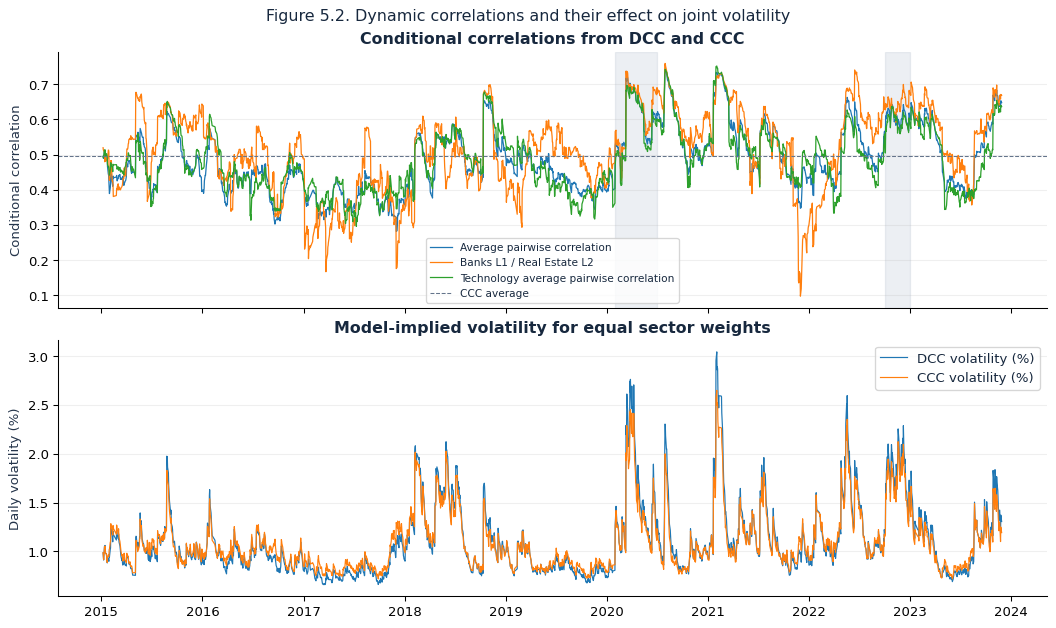

In [6]:
interactions = analyze_interactions(data, sample, config, output)

### Output 6 One-session VaR and expected shortfall

Compare historical simulation, rolling normal variance–covariance, EWMA, conditional GARCH-family forecasts and filtered historical simulation on the same holdout. The historical estimators and conditional-model fits use information available through the preceding session. For a left-tail return quantile $q_{\alpha}$ of the standardized innovation, $\mathrm{VaR}_{1-\alpha,t}=-(\mu_t+\sigma_t q_{\alpha})$. Replace the quantile with the integrated tail mean for ES. A common GARCH-t specification and one confidence level at a time support cross-sector ranking. High-VaR spell lengths use sector-specific retrospective percentile thresholds on the holdout and describe duration. EVT is an optional extension that would require a justified threshold and tail sample.

,sector,model,confidence_pct,n_test,first_date,last_date,mean_var_pct,mean_es_pct,last_var_pct,last_es_pct
4,Banks L1,GARCH-t,99,742,2023-11-28,2026-11-20,3.2732,4.5906,2.9996,4.2186
16,Technology L1,GARCH-t,99,742,2023-11-28,2026-11-20,4.6651,6.8347,6.1730,8.6876
28,Consumer Goods L1,GARCH-t,99,742,2023-11-28,2026-11-20,2.3329,3.1833,1.9707,2.6382
40,Real Estate L2,GARCH-t,99,742,2023-11-28,2026-11-20,4.3510,5.8038,4.0813,5.4023
52,Steel L4,GARCH-t,99,742,2023-11-28,2026-11-20,4.3547,5.8449,3.9683,5.4451


,sector,confidence_pct,rank_var_high_to_low,rank_es_high_to_low,mean_es_minus_var_pct
4,Banks L1,99,4,4,1.3175
5,Banks L1,95,4,4,0.9549
16,Technology L1,99,1,1,2.1697
17,Technology L1,95,3,1,1.4620
28,Consumer Goods L1,99,5,5,0.8504
29,Consumer Goods L1,95,5,5,0.6481
40,Real Estate L2,99,3,3,1.4528
41,Real Estate L2,95,1,3,1.1572
52,Steel L4,99,2,2,1.4902
53,Steel L4,95,2,2,1.1686


,sector,model,confidence_pct,holdout_quantile,var_threshold_pct,n_test,n_high_var_sessions,n_spells,mean_observed_duration_sessions,median_observed_duration_sessions,p90_observed_duration_sessions,max_observed_duration_sessions
0,Banks L1,GARCH-t,99,0.9,4.7546,742,75,12,6.2500,3.5,14.9,20
1,Technology L1,GARCH-t,99,0.9,6.4228,742,75,14,5.3571,4.0,14.3,19
2,Consumer Goods L1,GARCH-t,99,0.9,3.1134,742,75,12,6.2500,3.0,17.9,25
3,Real Estate L2,GARCH-t,99,0.9,7.0122,742,75,22,3.4091,1.0,9.8,13
4,Steel L4,GARCH-t,99,0.9,5.7416,742,75,16,4.6875,1.5,14.5,20


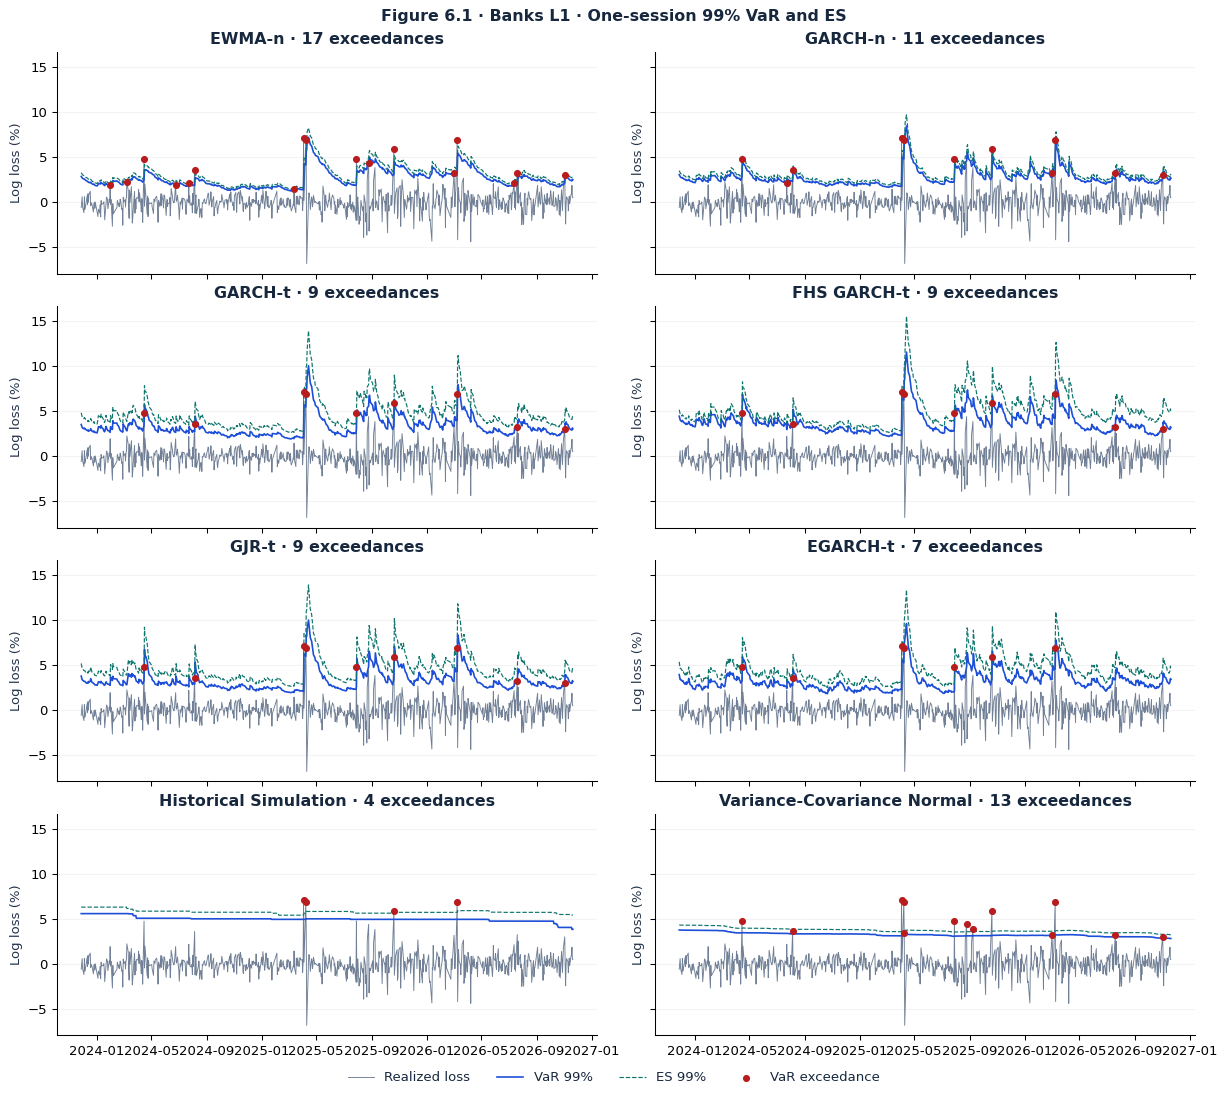

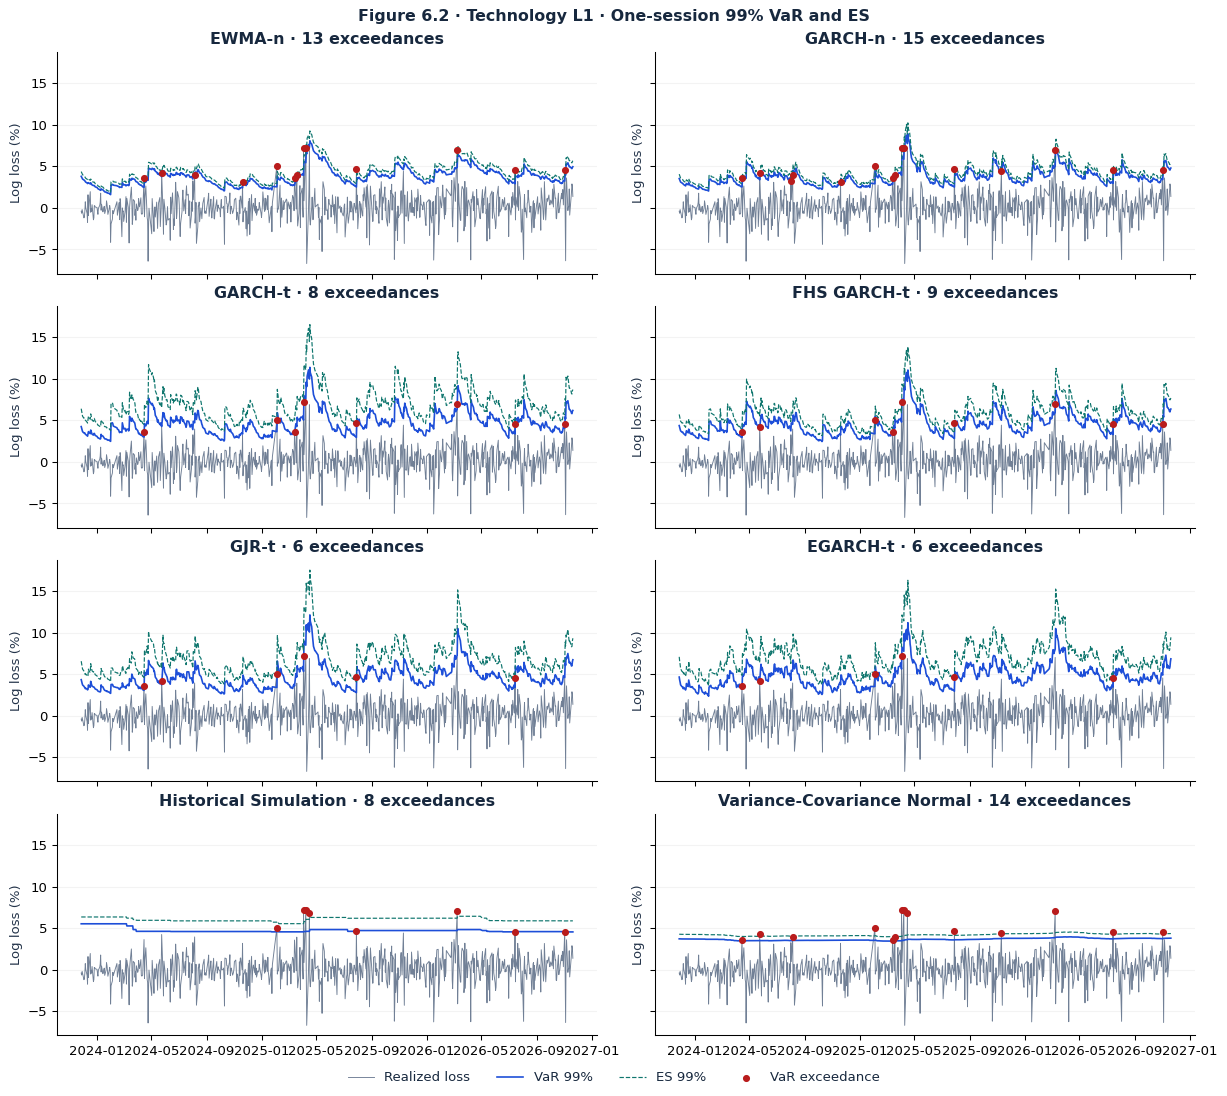

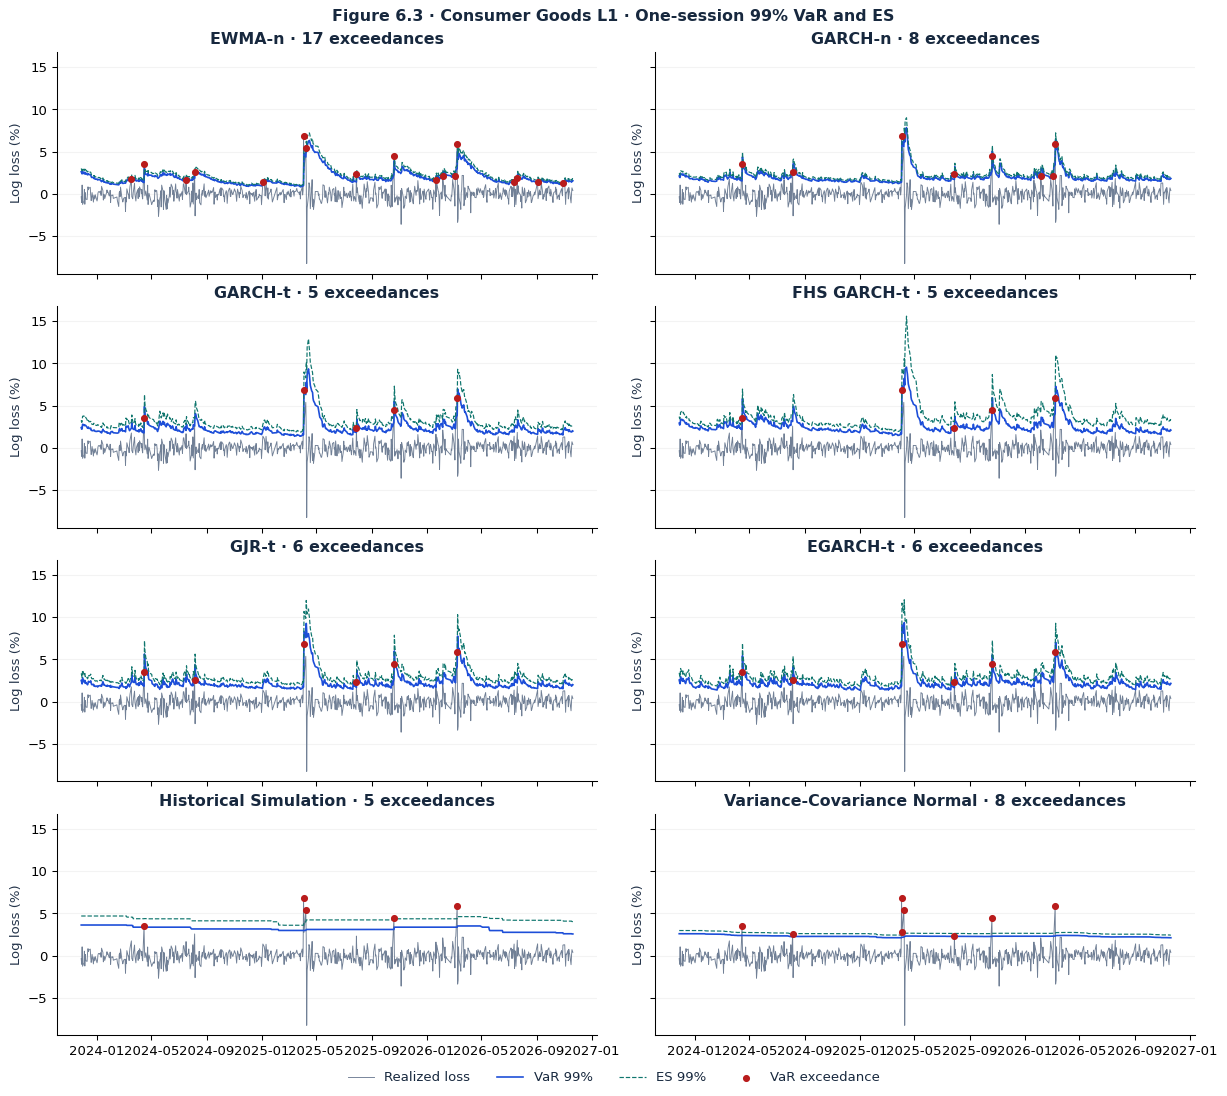

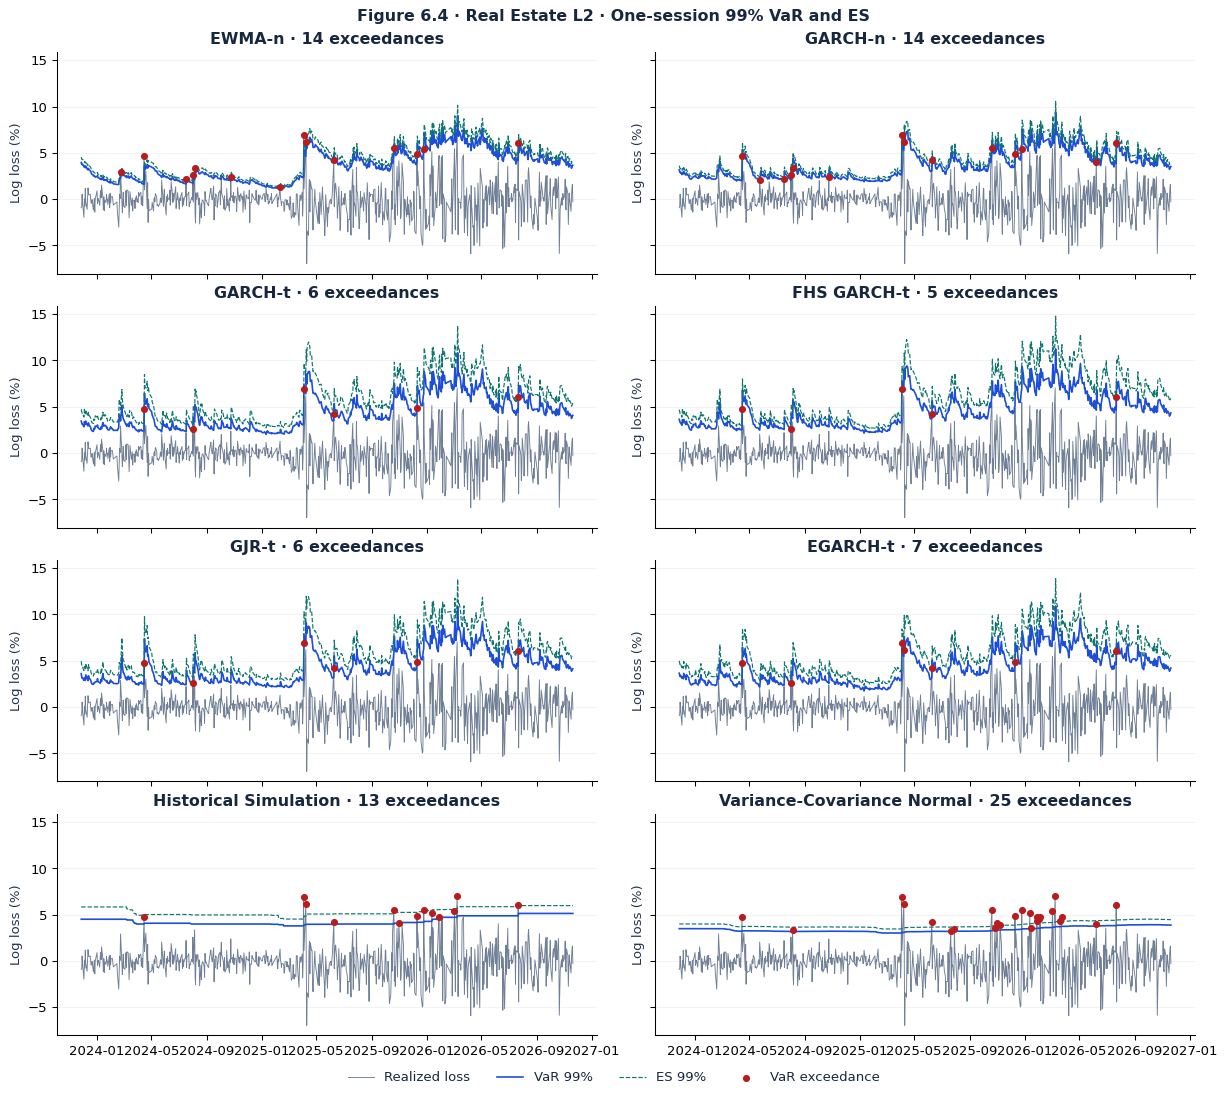

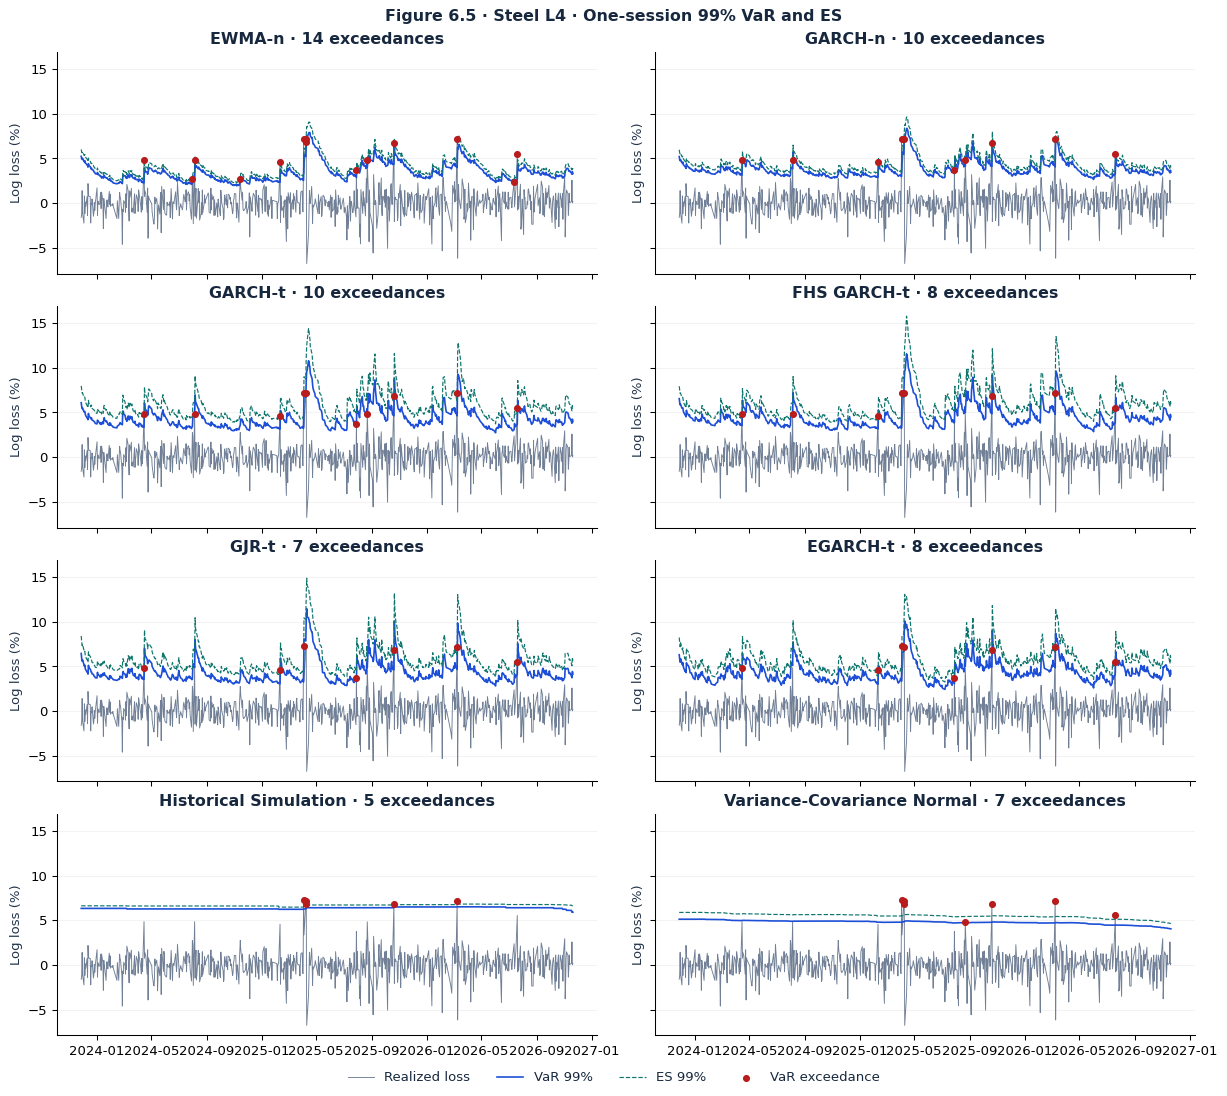

In [7]:
forecast = forecast_volatility(sample, config, output, fit, save=False)
risk = forecast_risk(forecast, config, output, data=data)

## Problem 2 Statistical significance

### Output 7 Forecast evaluation backtesting inference and robustness

**Variance evaluation.** Examine ACF of standardized residuals and their squares, Ljung–Box, ARCH-LM and admissibility. Refit using the latest 1,000 known observations every 20 sessions and update one-step forecasts within the block as returns arrive. Use the same squared ARMA innovation as the close-only variance proxy across models in the sector. Compare QLIKE, MSE and MAE. The Diebold–Mariano comparisons use aligned one-day loss differences, HAC uncertainty and Holm adjustment by sector and loss family.

**Risk evaluation.** Test VaR coverage and hit dependence with Kupiec, Christoffersen and a lagged-hit dynamic-quantile test. The DQ reference uses simulated Bernoulli hits under the nominal null. Compare quantile loss and joint VaR–ES FZ0 on their valid domains, and report an ES calibration moment with HAC uncertainty. Basel zones are descriptive for the last 250 forecasts at 99%. Tail backtests have low power with few hits.

**Cross-sector inference and robustness.** Resample contiguous date blocks jointly across all five sectors. Test the ten paired differences in realized sample volatility and in GARCH-t persistence using the aligned training dates. The primary bootstrap uses 20-session blocks. Its 40-session sensitivity uses the same requested draws for volatility and caps the persistence refits at 199. Mean filtering is estimated before the bootstrap. Report pointwise intervals and Holm-adjusted p-values within each metric/block family. The full-sample and subperiod estimates are retrospective. The expanding vs rolling GARCH-t test uses the same holdout dates and variance proxy. Examine whether results survive changes in specification, innovation distribution and period.

,sector,model,status,admissible,mean_reverting,LB(10) z p,LB(10) z² p,ARCH-LM(10) z stat,ARCH-LM(10) z p,diagnostic_n
0,Banks L1,EWMA-n,fit,True,False,0.0223,0.3855,10.6581,0.3848,2204
1,Banks L1,GARCH-n,fit,True,True,0.0271,0.4682,9.7795,0.4600,2204
2,Banks L1,GARCH-t,fit,True,True,0.0274,0.5223,9.0078,0.5314,2204
3,Banks L1,GJR-t,fit,True,True,0.0282,0.3931,10.5764,0.3915,2204
4,Banks L1,EGARCH-t,fit,True,True,0.0356,0.4719,9.5582,0.4801,2204
5,Technology L1,EWMA-n,fit,True,False,0.7989,0.9288,4.2918,0.9332,2204
6,Technology L1,GARCH-n,fit,True,True,0.8472,0.6681,7.7636,0.6519,2204
7,Technology L1,GARCH-t,fit,True,True,0.8251,0.7267,6.8057,0.7437,2204
8,Technology L1,GJR-t,fit,True,True,0.8120,0.5455,8.5695,0.5734,2204
9,Technology L1,EGARCH-t,fit,True,True,0.7641,0.6489,7.5389,0.6738,2204


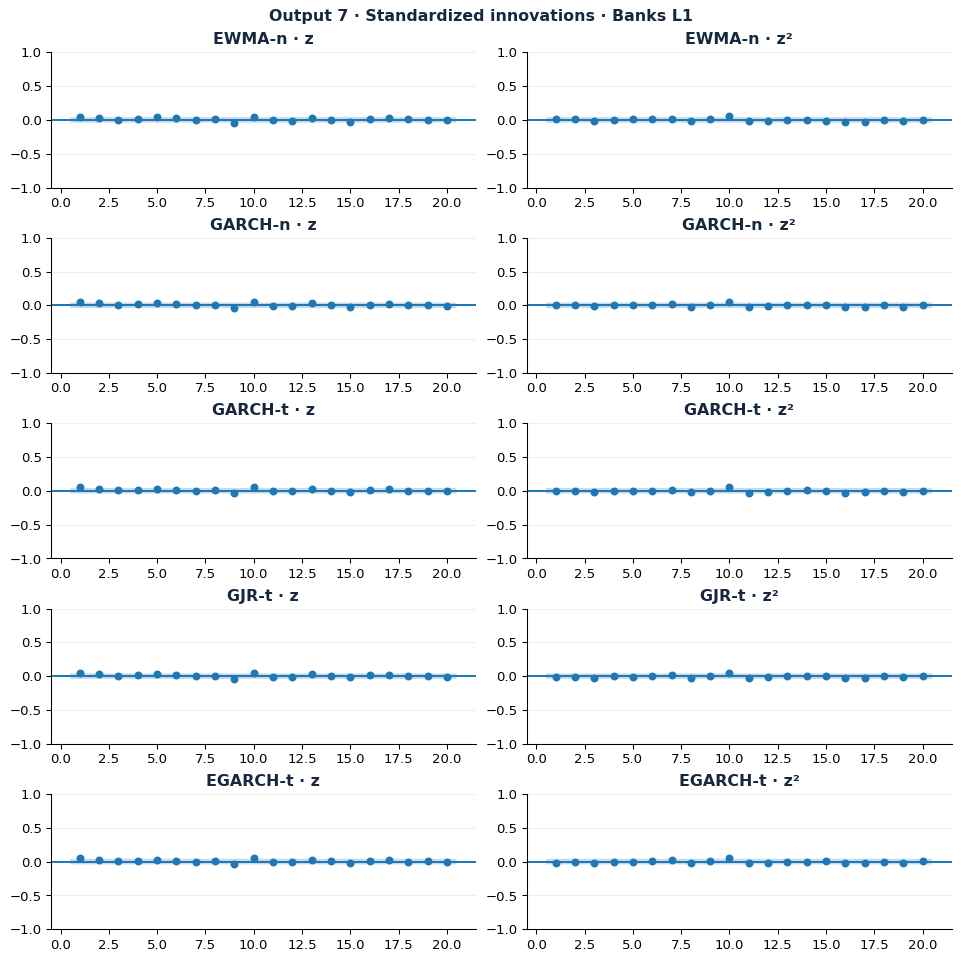

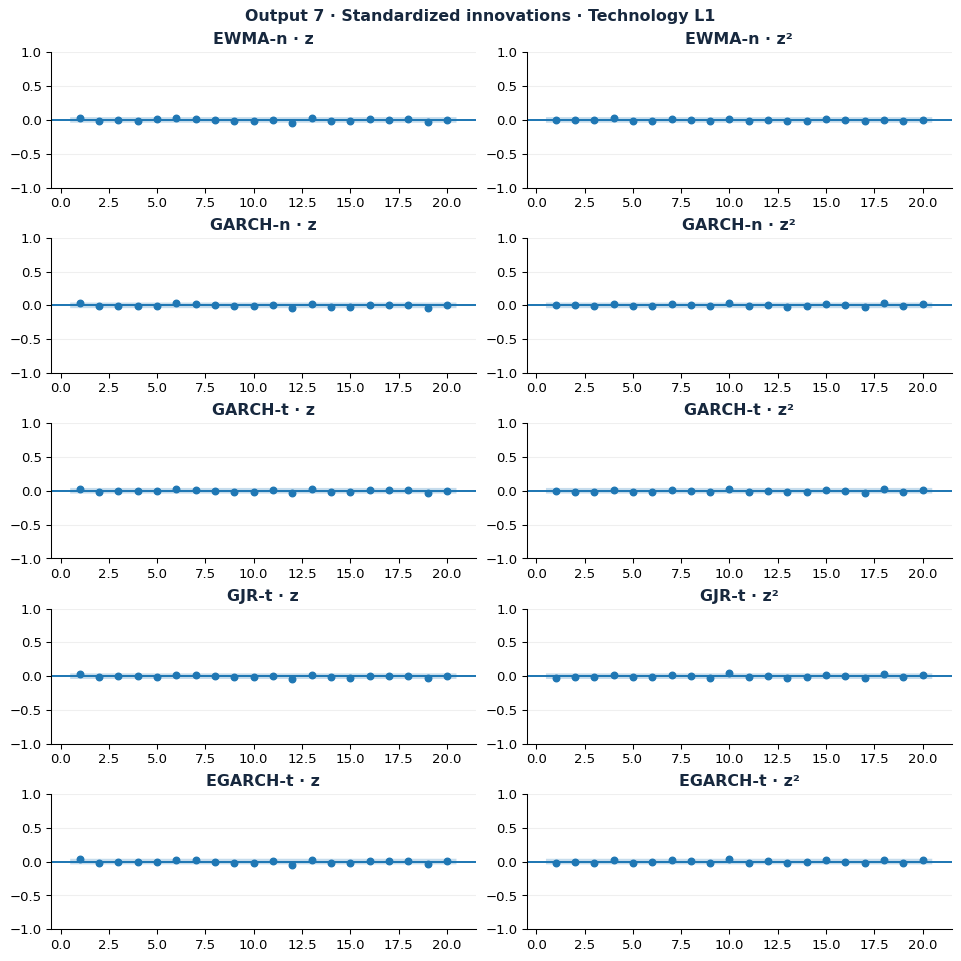

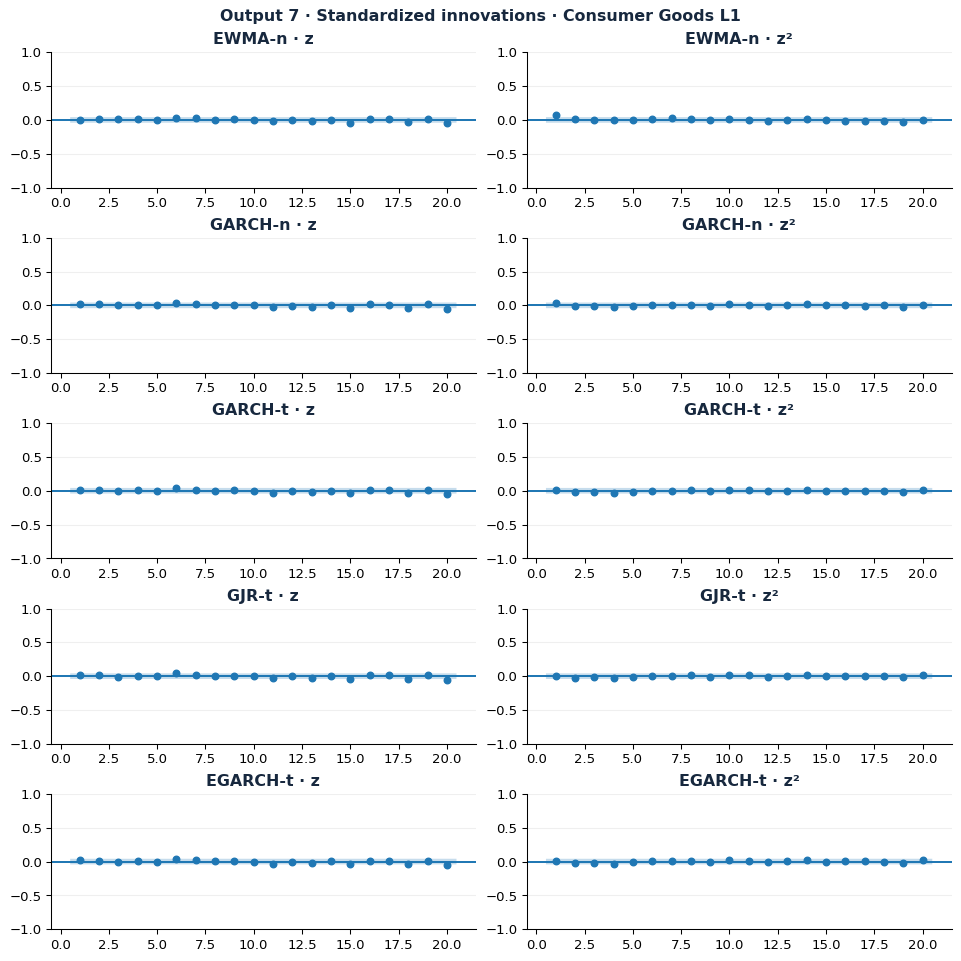

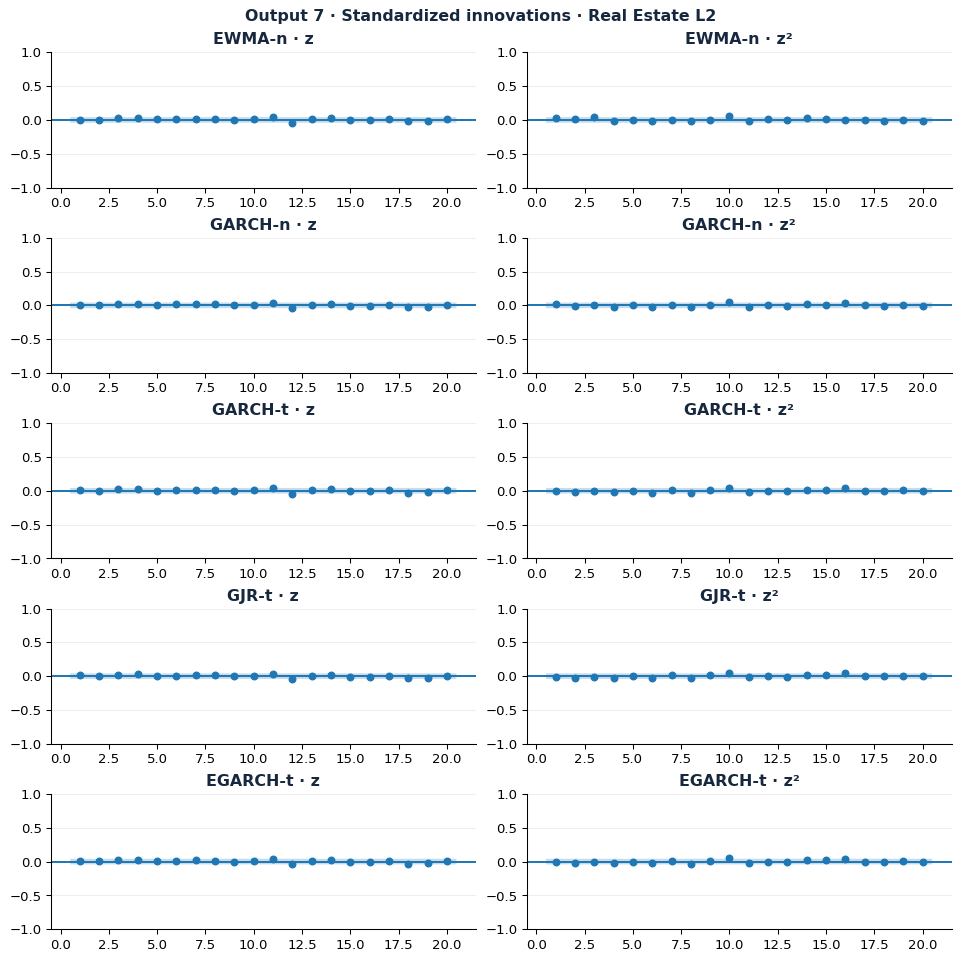

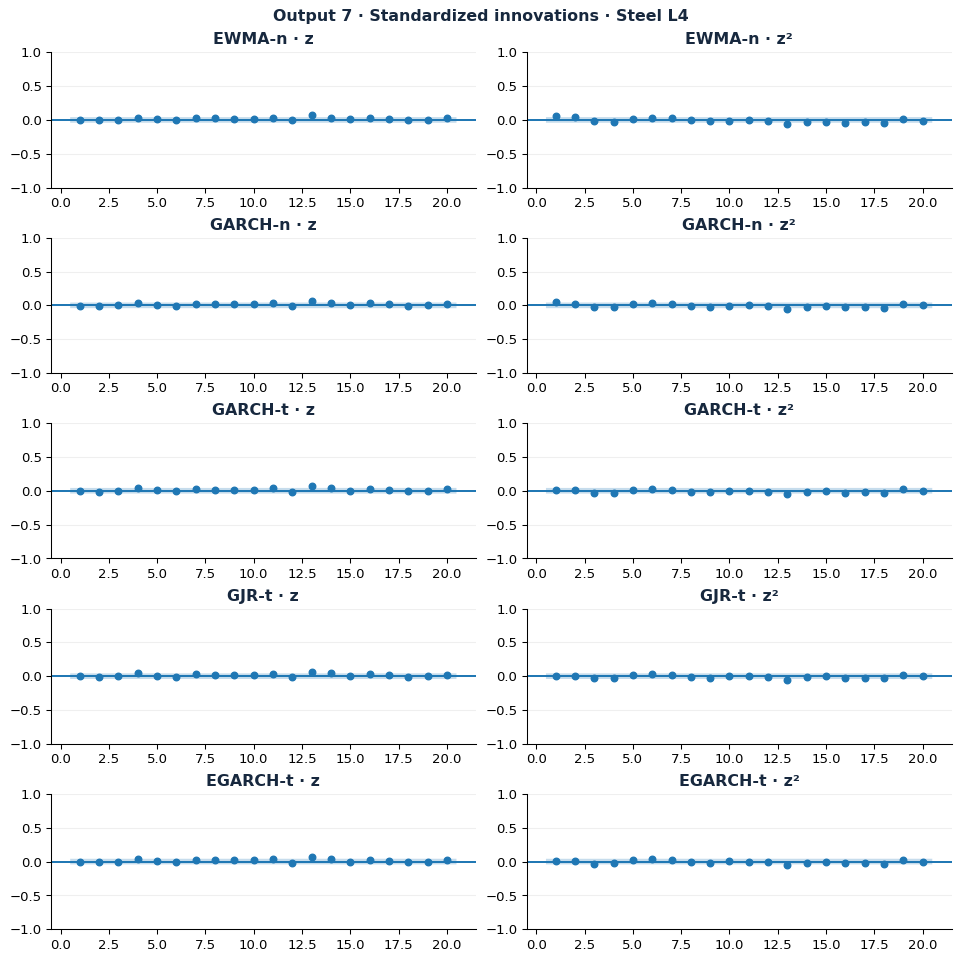

,sector,model,n_test,mse,mae,qlike
0,Banks L1,EGARCH-t,742,19.7906,1.9122,1.2987
1,Banks L1,GARCH-n,742,19.9091,1.8717,1.3028
2,Banks L1,GARCH-t,742,20.3957,1.9683,1.3115
3,Banks L1,GJR-t,742,20.2194,1.9778,1.3148
4,Banks L1,EWMA-n,742,20.3181,1.8470,1.3939
5,Consumer Goods L1,EGARCH-t,742,12.1928,1.0029,0.6168
6,Consumer Goods L1,GJR-t,742,12.4204,1.0371,0.6426
7,Consumer Goods L1,GARCH-n,742,13.1616,1.0314,0.6746
8,Consumer Goods L1,GARCH-t,742,13.5616,1.0906,0.6860
9,Consumer Goods L1,EWMA-n,742,13.8112,1.0690,0.9187


Banks L1 · QLIKE thấp nhất: EGARCH-t. MSE: EGARCH-t. MAE: EWMA-n.
Consumer Goods L1 · QLIKE thấp nhất: EGARCH-t. MSE: EGARCH-t. MAE: EGARCH-t.
Real Estate L2 · QLIKE thấp nhất: GARCH-t. MSE: EWMA-n. MAE: GARCH-n.
Steel L4 · QLIKE thấp nhất: GJR-t. MSE: GJR-t. MAE: EWMA-n.
Technology L1 · QLIKE thấp nhất: GJR-t. MSE: GARCH-n. MAE: GARCH-n.


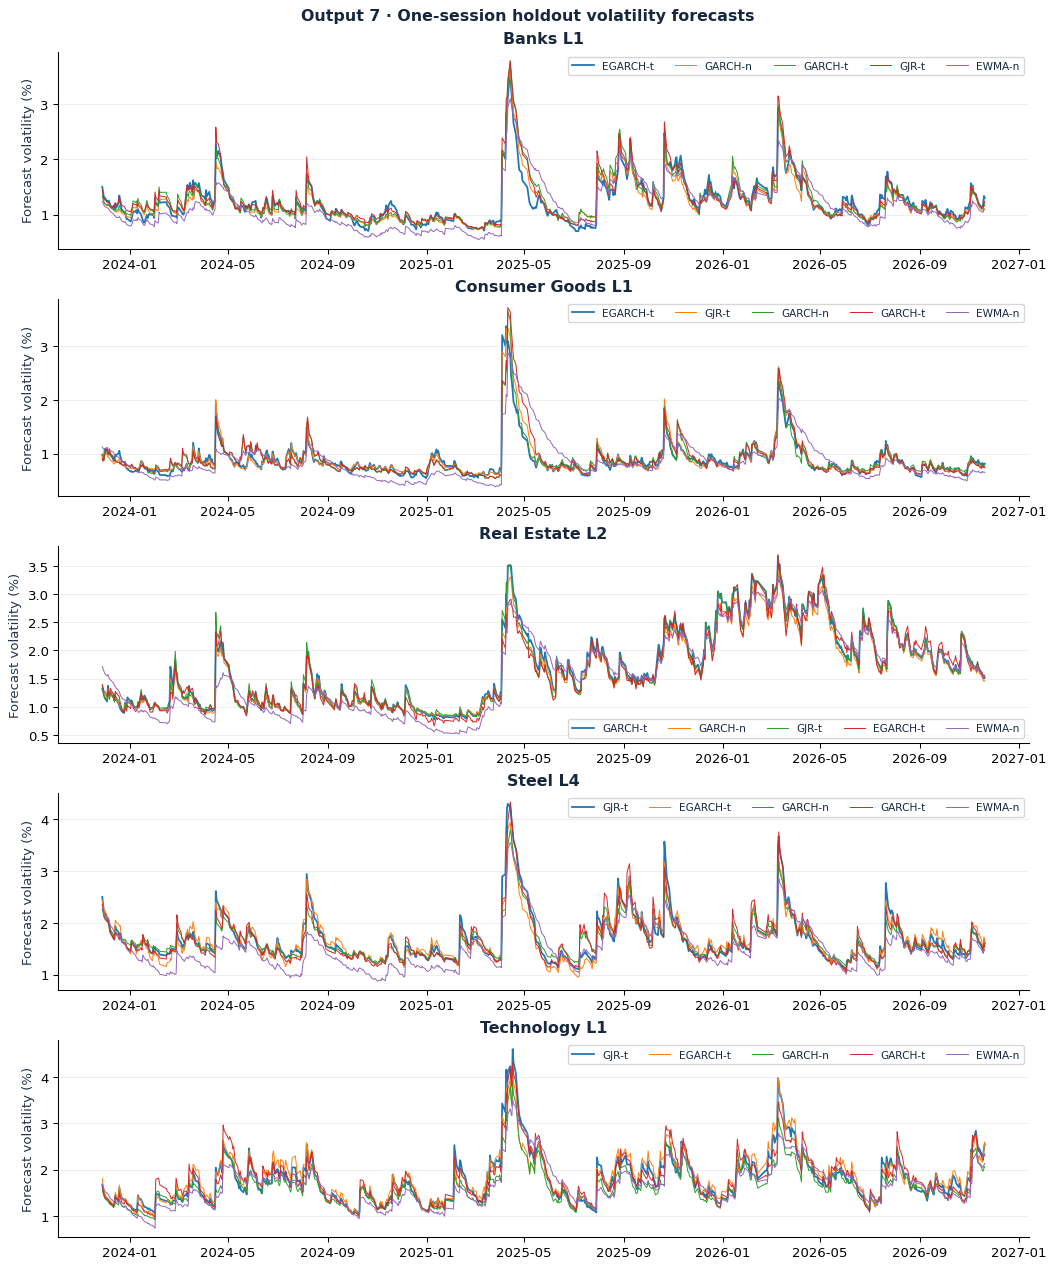

VaR 99% · Kupiec UC, Christoffersen IND/CC và DQ Monte Carlo


,sector,model,n_test,expected_hits,hits,hit_rate_pct,uc_p,exact_binomial_p,ind_p,cc_p,dq_p_mc,quantile_loss,basel_250_hits,basel_250_zone
0,Banks L1,EWMA-n,742,7.42,17,2.2911,0.0025,0.0022,0.3716,0.0069,0.0431,0.0612,5.0,Yellow
2,Banks L1,GARCH-n,742,7.42,11,1.4825,0.2177,0.1913,0.5648,0.3964,0.2188,0.0569,4.0,Green
4,Banks L1,GARCH-t,742,7.42,9,1.2129,0.5727,0.5756,0.6380,0.7636,0.1635,0.0558,3.0,Green
6,Banks L1,FHS GARCH-t,742,7.42,9,1.2129,0.5727,0.5756,0.6380,0.7636,0.1635,0.0563,3.0,Green
8,Banks L1,GJR-t,742,7.42,9,1.2129,0.5727,0.5756,0.6380,0.7636,0.1635,0.0550,3.0,Green
10,Banks L1,EGARCH-t,742,7.42,7,0.9434,0.8757,1.0000,0.7148,0.9240,0.0872,0.0548,1.0,Green
12,Technology L1,EWMA-n,742,7.42,13,1.7520,0.0628,0.0601,0.4956,0.1404,0.0775,0.0630,3.0,Green
14,Technology L1,GARCH-n,742,7.42,15,2.0216,0.0140,0.0139,0.4311,0.0359,0.0114,0.0611,3.0,Green
16,Technology L1,GARCH-t,742,7.42,8,1.0782,0.8326,0.7129,0.6760,0.8962,0.7586,0.0579,3.0,Green
18,Technology L1,FHS GARCH-t,742,7.42,9,1.2129,0.5727,0.5756,0.6380,0.7636,0.5586,0.0584,3.0,Green


VaR 95% · Kupiec UC, Christoffersen IND/CC và DQ Monte Carlo


,sector,model,n_test,expected_hits,hits,hit_rate_pct,uc_p,exact_binomial_p,ind_p,cc_p,dq_p_mc,quantile_loss
1,Banks L1,EWMA-n,742,37.1,38,5.1213,0.8800,0.8660,0.4333,0.7273,0.9034,0.1514
3,Banks L1,GARCH-n,742,37.1,28,3.7736,0.1097,0.1511,0.3926,0.1931,0.3380,0.1491
5,Banks L1,GARCH-t,742,37.1,30,4.0431,0.2167,0.2727,0.1487,0.1644,0.2593,0.1492
7,Banks L1,FHS GARCH-t,742,37.1,28,3.7736,0.1097,0.1511,0.3926,0.1931,0.3380,0.1519
9,Banks L1,GJR-t,742,37.1,31,4.1779,0.2909,0.3535,0.0423,0.0729,0.1178,0.1497
11,Banks L1,EGARCH-t,742,37.1,33,4.4474,0.4819,0.5552,0.2409,0.3926,0.4073,0.1477
13,Technology L1,EWMA-n,742,37.1,36,4.8518,0.8523,0.9329,0.0551,0.1562,0.0197,0.1878
15,Technology L1,GARCH-n,742,37.1,35,4.7170,0.7211,0.8005,0.0624,0.1654,0.0953,0.1845
17,Technology L1,GARCH-t,742,37.1,37,4.9865,0.9866,1.0000,0.0485,0.1429,0.0350,0.1857
19,Technology L1,FHS GARCH-t,742,37.1,38,5.1213,0.8800,0.8660,0.4333,0.7273,0.0108,0.1869


VaR–ES 99% · FZ0, đối chiếu các phiên vượt VaR và kiểm định hiệu chỉnh trung bình


,sector,model,hits,realized_tail_loss_pct,predicted_es_on_hits_pct,es_gap_on_hits_pct,es_moment_mean_pct,es_hac_se,es_moment_p,fz0_n_valid,fz0_loss
0,Banks L1,EWMA-n,17,3.8402,2.6826,1.1576,3.0645,1.3290,0.0211,742,2.3086
2,Banks L1,GARCH-n,11,4.6694,3.1448,1.5247,2.4548,1.2028,0.0413,742,1.9778
4,Banks L1,GARCH-t,9,5.1161,4.5556,0.5605,0.9227,1.0144,0.3630,742,1.7557
6,Banks L1,FHS GARCH-t,9,5.1161,4.9894,0.1267,0.5023,0.8712,0.5642,742,1.7670
8,Banks L1,GJR-t,9,5.1161,4.6794,0.4367,0.8058,0.9619,0.4022,742,1.7437
10,Banks L1,EGARCH-t,7,5.6891,4.6449,1.0442,0.9204,1.0109,0.3626,742,1.7321
12,Technology L1,EWMA-n,13,4.8204,3.8607,0.9597,2.0032,0.8845,0.0235,742,1.9972
14,Technology L1,GARCH-n,15,4.6879,4.0160,0.6718,1.8633,0.8144,0.0221,742,1.9212
16,Technology L1,GARCH-t,8,5.0284,5.7664,-0.7380,-1.0127,0.4643,0.0292,742,1.7767
18,Technology L1,FHS GARCH-t,9,4.9399,4.9021,0.0378,0.0637,0.5219,0.9028,742,1.7926


... (3 outputs left out)

,Annualized vol (%),GARCH-t persistence,Lowest QLIKE,Lowest 99% quantile loss,99% VaR hits,99% expected hits,99% CC p-value,Lowest 99% FZ0
sector,,,,,,,,
Banks L1,24.0351,0.9816,EGARCH-t,EGARCH-t,7,7.42,0.9240,EGARCH-t
Technology L1,23.7423,0.9780,GJR-t,EGARCH-t,6,7.42,0.8221,EGARCH-t
Consumer Goods L1,15.7453,0.9557,EGARCH-t,EGARCH-t,6,7.42,0.8221,EGARCH-t
Real Estate L2,22.7851,0.9543,GARCH-t,GARCH-t,6,7.42,0.8221,GARCH-t
Steel L4,28.7955,0.9750,GJR-t,EGARCH-t,8,7.42,0.8962,EGARCH-t


Trên 2,966 phiên lợi suất chung, Steel L4 có độ biến động quy năm cao nhất (28.80%) và Consumer Goods L1 thấp nhất (15.75%).
Trong mẫu huấn luyện chung, độ dai dẳng GARCH-t cao nhất ở Banks L1 (0.9816) và thấp nhất ở Real Estate L2 (0.9543).


,sector,persistence,n_high_var_sessions,n_spells,mean_observed_duration_sessions,max_observed_duration_sessions,median_observed_duration_sessions
0,Banks L1,0.9816,75,12,6.2500,20,3.5
1,Technology L1,0.9780,75,14,5.3571,19,4.0
2,Consumer Goods L1,0.9557,75,12,6.2500,25,3.0
3,Real Estate L2,0.9543,75,22,3.4091,13,1.0
4,Steel L4,0.9750,75,16,4.6875,20,1.5


,measure,n_sectors,spearman_rho_descriptive
0,mean_observed_duration_sessions,5,0.5643
1,max_observed_duration_sessions,5,0.2052


In [8]:
publish_volatility_evaluation(fit, forecast, output)
backtest = backtest_risk(data, sample, fit, forecast, risk, config, output)

In [9]:
inference = evaluate_inference(
    data, sample, fit, forecast, config, output, bootstrap_reps=bootstrap_reps
)

Output 7 · Aligned one-step forecast losses and Diebold–Mariano comparisons
DM uses Bartlett HAC(5) and Holm adjustment within each sector/loss family. Negative loss differences favor model A. Heavy tails can make inference imprecise.


,sector,loss,pairs,valid_tests,holm_rejections
0,Banks L1,QLIKE,10,10,0
1,Banks L1,MAE,10,10,4
2,Technology L1,QLIKE,10,10,0
3,Technology L1,MAE,10,10,6
4,Consumer Goods L1,QLIKE,10,10,0
5,Consumer Goods L1,MAE,10,10,0
6,Real Estate L2,QLIKE,10,10,0
7,Real Estate L2,MAE,10,10,6
8,Steel L4,QLIKE,10,10,0
9,Steel L4,MAE,10,10,4


Output 7 · Paired date-block bootstrap on the common training sample
Primary block length 20 sessions. Length 40 checks sensitivity. Basic intervals are pointwise and Holm families are defined by metric and block length. GARCH-t inference conditions on the previously estimated ARMA mean filters. Persistent shocks spanning block boundaries may be partly broken by resampling.


,metric,sector_a,sector_b,difference_a_minus_b,ci_low,ci_high,p_holm,reps_success
0,annualized_volatility_pct,Banks L1,Technology L1,3.0341,1.4493,4.5790,0.025,399
1,annualized_volatility_pct,Banks L1,Consumer Goods L1,9.3280,7.7028,10.9249,0.025,399
2,annualized_volatility_pct,Banks L1,Real Estate L2,4.6665,2.8603,6.3467,0.025,399
3,annualized_volatility_pct,Banks L1,Steel L4,-4.7291,-6.7737,-2.6617,0.025,399
4,annualized_volatility_pct,Technology L1,Consumer Goods L1,6.2939,5.0159,7.6417,0.025,399
5,annualized_volatility_pct,Technology L1,Real Estate L2,1.6324,0.1012,3.2371,0.040,399
6,annualized_volatility_pct,Technology L1,Steel L4,-7.7632,-9.7180,-6.0736,0.025,399
7,annualized_volatility_pct,Consumer Goods L1,Real Estate L2,-4.6615,-6.0321,-3.3188,0.025,399
8,annualized_volatility_pct,Consumer Goods L1,Steel L4,-14.0572,-15.7882,-12.0817,0.025,399
9,annualized_volatility_pct,Real Estate L2,Steel L4,-9.3957,-11.2507,-7.5139,0.025,399


Output 7 · Retrospective full-sample and period-specific parameter estimates


period,Full sample,Pre-COVID,COVID (2020–2021),Post-COVID (2022+)
sector,,,,
Banks L1,0.9811,0.9850,0.8960,0.9723
Consumer Goods L1,0.9521,0.9722,0.8928,0.9570
Real Estate L2,0.9890,0.9757,0.9282,1.0000
Steel L4,0.9633,0.9614,0.9007,0.9787
Technology L1,0.9891,0.9758,0.9261,1.0000


Output 7 · Rolling versus expanding GARCH-t forecasting windows


,sector,n_matched,rolling_qlike,expanding_qlike,status
0,Banks L1,742,1.3115,1.2915,Fit
1,Technology L1,742,2.0651,2.0628,Fit
2,Consumer Goods L1,742,0.6860,0.6505,Fit
3,Real Estate L2,742,1.8446,1.8584,Fit
4,Steel L4,742,1.8426,1.8157,Fit


## Problem 3 Economic interpretation

In [10]:
findings = write_findings(data, fit, interactions, risk, backtest, inference, config, output)
display(Markdown(findings))

# Group 10 research findings

## Measurement

Across 2,966 matched daily returns, **Steel L4** had the highest annualized sample volatility (28.80%) and **Consumer Goods L1** the lowest (15.75%). These estimates describe the entire observed sample.

Under the same training-sample GARCH-t specification, persistence was highest for **Banks L1** (0.9816, half-life 37.4 sessions) and lowest for **Real Estate L2** (0.9543, half-life 14.8 sessions). Persistence measures how slowly a variance shock decays, while sample volatility measures the overall scale of fluctuations.

## Sector interactions

The BIC-selected VAR lag was 0. The reported VAR(1) was stable. The Holm-adjusted Granger tests rejected 0 of 20 directed hypotheses at 5%. These tests concern predictive information in lagged returns.

The DCC fit reported a correlation quasi-log-likelihood improvement over CCC of 169.75 and a correlation decay coefficient sum of 0.9784. The likelihood comparison is descriptive. A DCC correlation describes conditional co-movement and leaves the channels behind that co-movement unidentified.

Among the ten matched pairs, the largest time-series standard deviation of estimated DCC correlation was for **Consumer Goods L1 and Real Estate L2** (0.125). Compare the 05-series regime and daily-correlation tables before discussing any stress episode.

The Bank–Real Estate conditional-correlation averages were 0.472 in Pre-COVID, 0.620 in Early COVID-19, 0.645 in Late-2022 financial stress. A shared exposure to financing conditions is one plausible channel for that movement. Investigating it requires dated credit, liquidity or property-finance indicators.

## Downside risk and statistical significance

On the GARCH-t holdout paths at 99%, **Technology L1** had the highest average VaR (4.67% log loss) and **Technology L1** the highest average ES (6.83% log loss). The 06-series tables give ranks by confidence level and method. Changes in rank reflect both volatility and tail shape.

With Gaussian GARCH, **Steel L4** had the highest average 99% ES (4.40%). Comparing the two fits shows why a sector risk ranking can depend on the innovation distribution.

The longest observed high-VaR spell was 25 trading sessions for **Consumer Goods L1**. The cutoffs are the sectors' own holdout 90th percentiles of GARCH-t 99% VaR. The duration comparison is retrospective and relative to each sector's usual risk level.

For annualized-volatility, the bootstrap rejected 10 of 10 at block length 20 and 9 of 10 at block length 40 after Holm correction at 5%. It uses matched training observations. Confidence intervals and the finite simulation resolution are in `07_cross_sector_bootstrap.csv`.

For GARCH-t persistence, the bootstrap rejected 0 of 10 at block length 20 and 0 of 10 at block length 40 after Holm correction at 5%. It uses matched training observations. Confidence intervals and the finite simulation resolution are in `07_cross_sector_bootstrap.csv`.

The QLIKE Diebold–Mariano tests rejected 0 of 50 comparisons after Holm adjustment. The QLIKE score rankings summarize observed performance. Use the tests to assess the uncertainty around those rankings.

The retrospective GARCH-t fits flagged a lack of mean reversion for Technology L1 in Post-COVID (2022+), Real Estate L2 in Post-COVID (2022+). These fits have no finite half-life under the reported specification.

The risk evaluation contains 80 sector–model–confidence results. At 99%, the lagged-hit DQ test rejected 13 of 40 testable paths at 5% before correction. With sparse tail hits, read the DQ, coverage and ES checks together with loss scores and their domain coverage.

## Interpreting the findings

A sector's volatility level, the persistence of a shock and the length of high-risk spells are distinct results. Use the paired bootstrap for cross-sector differences, the subperiod table for regime sensitivity and the forecast comparisons for performance in the holdout. The five baskets differ in ICB breadth and historical weights are unavailable. A mechanism remains a hypothesis until evidence tied to that mechanism is tested against dated sector results.

[Economic context, practical implications and sources](../economic_context.md)


The economic links below are hypotheses. The measured results identify differences in risk dynamics. Sector returns alone leave the credit, demand and earnings channels unidentified.

| Sector | Plausible channel and evidence to compare |
|---|---|
| Banks | Credit losses, deposit funding, and provisions can prompt several rounds of revisions to expected bank earnings. The IMF documented banking liquidity and asset-quality vulnerabilities in its 2025 consultation. If the estimates show persistent volatility or a stronger response to negative returns, compare those episodes with changes in non-performing loans, provisioning, or funding conditions before attributing a channel. [IMF Country Report No. 25/283, pp. 12–13](https://www.imf.org/en/-/media/files/publications/cr/2025/english/1vnmea2025001-source-pdf.pdf) |
| Real Estate | Refinancing, project approvals, and buyer demand evolve at different speeds. The World Bank documented credit concentration in property and implementation bottlenecks in Vietnamese housing. If bank–property correlations rise during a stress period, shared exposure to financing conditions is one candidate explanation. Sector equity returns and correlations alone cannot establish contagion. [World Bank, Viet Nam Economic Update, May 2026, Box 2](https://documents1.worldbank.org/curated/en/099740005122628080/pdf/IDU-2ee874ce-e0c0-462b-9571-99e553ef83c9.pdf) |
| Technology | News about contracts, customer IT budgets, and long-term growth can shift expected cash flows and valuations. FPT’s 2025 annual report illustrates some of these exposures through its foreign IT services business. This issuer example supplies a channel to examine. Its weight or influence in the exported index would require constituent records. [FPT, Annual Report 2025, IT Services for Foreign Markets](https://bctn2025.fpt.com/business-performance-analysis/technology-sector/it-services-for-foreign-markets/) |
| Consumer Goods | Household purchasing power and changes in input costs can affect sales and margins. Repeated purchases can steady demand for some goods, while other categories are more income-sensitive. The National Statistics Office publishes retail sales of goods and services as an aggregate demand indicator. Its scope differs from the listed Consumer Goods L1 basket, so it can be used as background or a separately tested proxy. [National Statistics Office of Viet Nam, 2025 Socio-economic Situation, Section 6](https://www.nso.gov.vn/en/data-and-statistics/2026/01/socio-economic-situation-in-the-fourth-quarter-and-2025/) |
| Steel | Domestic building and public infrastructure can affect volumes. Ore, coal, scrap, and trade developments can affect margins. Worldsteel linked its Viet Nam demand outlook to construction and public investment, and Vietnam Steel Corporation discussed exposure to raw-material prices and imports. These sources motivate checking a commodity-cost shock or construction slowdown against dates of large steel-index moves. [World Steel Association, Short Range Outlook, October 2026](https://worldsteel.org/media/press-releases/2026/worldsteel-short-range-outlook-october-2026/) · [Vietnam Steel Corporation, Annual Report 2025, pp. 32–33](https://fs.vnsteel.vn/Uploads/PublicOther/2026/04/14/16/en-annualreport-2025-signed.pdf) |

## Practical implications and limits

**Bank.** For a trading book with sector equity exposure, compare one-day VaR and ES forecasts with subsequent breaches, and use stress scenarios for days with sharper losses than the historical sample shows. A slower estimated decay can support monitoring for several sessions after a shock. Sector equity VaR measures price risk. Loan losses require borrower and collateral information.

**Fund.** Sector forecasts inform exposure monitoring. Conditional correlations help assess whether historically different sectors still diversify one another during stress. Portfolio risk and hedge design also require actual holdings and weights, available hedge instruments, liquidity, transaction costs, and exposure to the hedge benchmark.

**Investor.** Use the volatility and downside-risk results to compare how quickly risk rose, how long it remained elevated, and how severe modelled tail losses were. A sector with lower average volatility can still suffer a large loss. Historical point estimates apply to the selected listed baskets, dates, and models.

**Statistical and operational boundaries.** Granger tests address whether lagged returns improve forecasts. DCC describes changes in conditional co-movement. Neither test separately identifies a common shock or establishes a direction of transmission. A ranking or a wide confidence interval calls for cautious language about differences. Rare exceptions at 99% limit tail-backtest power, and close-only observations provide a noisy proxy for daily variance. The exercise does not capture intraday moves, actual portfolio execution, or business cash flows.

**Future work.** Add point-in-time constituent weights and trading volumes, then compare unweighted and concentration-adjusted baskets. Add independently dated variables that correspond to the channels above, such as rates and credit indicators, property indicators, retail data, and steel-input prices. Test whether the channel explains future variation after controlling for broad market shocks and evaluate results across regimes and rolling windows. A dated event-study design with separately justified identification assumptions is a follow-up for causal questions.

## Method references

- [Hyndman and Athanasopoulos · Forecasting Principles and Practice, ARIMA](https://otexts.com/fpp3/arima.html)
- [RiskMetrics · Technical Document, 1996](https://www.msci.com/documents/10199/5915b101-4206-4ba0-aee2-3449d5c7e95a)
- [Bollerslev · GARCH, 1986](https://doi.org/10.1016/0304-4076(86)90063-1), [Glosten et al. · GJR, 1993](https://doi.org/10.1111/j.1540-6261.1993.tb05128.x), [Nelson · EGARCH, 1991](https://doi.org/10.2307/2938260)
- [Bollerslev · Constant conditional correlations, 1990](https://doi.org/10.2307/2109358), [Engle · Dynamic conditional correlation, 2002](https://doi.org/10.1198/073500102288618487)
- [Patton · Imperfect volatility proxies, 2011](https://public.econ.duke.edu/~ap172/Patton_vol_proxies_JoE_2011.pdf), [Diebold and Mariano · Forecast accuracy, 1995](https://users.ssc.wisc.edu/~behansen/718/DieboldMariano1995.pdf)
- [Kupiec · VaR coverage, 1995](https://fraser.stlouisfed.org/files/docs/publications/bog_feds/feds_1995-024.pdf), [Christoffersen · Conditional coverage, 1998](https://users.ssc.wisc.edu/~behansen/718/Christoffersen1998.pdf), [Engle and Manganelli · Dynamic quantile test, 2004](https://pages.stern.nyu.edu/rengle/CAVIAR.pdf)
- [Basel Committee · Traffic light backtesting, 1996](https://www.bis.org/publ/bcbsc223.pdf), [Nolde and Ziegel · VaR–ES calibration, 2017](https://doi.org/10.1214/17-AOAS1041), [Patton, Ziegel and Chen · FZ0, 2019](https://public.econ.duke.edu/~ap172/Patton_Ziegel_Chen_JoE_2019.pdf)
- [Politis and Romano · Circular block-resampling, technical report](https://statistics.stanford.edu/technical-reports/circular-block-resampling-procedure-stationary-data)
- [Barone-Adesi, Giannopoulos and Vosper · Filtered historical simulation, 1999](https://ideas.repec.org/a/wly/jfutmk/v19y1999i5p583-602.html)

The analysis follows the Group 10 outline, the ATFB midterm brief and the course notebook template. Group members should document their own contributions and the use of AI tools in the report appendices, as specified in the brief.